# UFC Fight Outcome Prediction

**Author:** Maksym Redchenko · **Student number:** C00302240
**Module:** Data Science & Machine Learning 1, Continuous Assessment Portfolio, Project 2
**GitHub:** https://github.com/S5in/Data-Science-and-Machine-Learning

This notebook asks whether the winner of a UFC fight can be predicted from information that was available **before** the fight. It follows the CRISP-DM process from the lectures.

1. Business understanding
2. Setup
3. Data infrastructure: building the SQLite database
4. Data understanding
5. Data quality summary
6. Provenance, licence and ethics
7. Data preparation
8. Feature engineering
9. Modelling (including 9.9, improving the model)
10. Conclusion

In [1]:
# Author: Maksym Redchenko
# Student number: C00302240
# Project 2: UFC Fight Outcome Prediction (Data Science & ML 1 CA portfolio)

## 1. Business understanding

**Question.** Can engineered features built only from information known before a fight predict its winner better than a simple baseline?

**Why it matters.** Fight prediction is used by analysts, broadcasters, fans and the betting industry. It is also a good data science problem, because the obvious data is full of traps. The main one is **data leakage**: accidentally using information from after the fight to predict it, which makes a model look far better than it really is.

**Type of analytics.** This is **predictive** analytics (will fighter A beat fighter B?), supported by **descriptive** analytics in Section 4 (how have UFC fights changed over 30 years?).

**Success criteria.** The final model is trained on older fights and tested on the most recent ones, with no shuffling. It is judged by:

- **Accuracy** compared with a naive baseline (Section 4.6 shows why choosing this baseline is less obvious than it sounds), and
- **Log loss**, which also rewards well-calibrated probabilities (a model that says 90% should be right about 90% of the time).

## 2. Setup

In [2]:
import re
import sqlite3
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, brier_score_loss

# --- Data locations ------------------------------------------------------
DATA_ZIP = Path("..") / "ufc_archive.zip"   # raw CSVs scraped from ufcstats.com
DB_PATH = Path("ufc.db")                    # SQLite database built by this notebook

# --- Dates that matter (explained in Section 4) ---------------------------
CORNER_RELIABLE_FROM = "2010-04-01"  # before this, the winner is always listed as 'red'
MODERN_RULES_FROM = "2001-01-01"     # earlier events used very different rules (Section 4.3)

# --- Modelling settings (Sections 8-9) ------------------------------------
MODEL_FROM = CORNER_RELIABLE_FROM    # fights used for training and testing
TEST_START = "2024-01-01"            # train before this date, test on and after it
ELO_START = 1500                     # every fighter's first Elo rating
ELO_K_OPTIONS = [16, 32, 64, 100, 150, 200, 300]
RANDOM_SEED = 42                     # makes the random fighter order reproducible
MIN_STAT_MINUTES = 5                 # rates (per minute, per 15 min) need at least one full round of data
VALID_AGE = (16, 55)                 # ages outside this range come from a wrong date of birth

# --- Plot style -----------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 3. Data infrastructure: building the SQLite database

### 3.1 The raw data

The data was scraped from **ufcstats.com**, the UFC's official statistics site. It arrives as a zip of CSV files, one per table.

In [3]:
with zipfile.ZipFile(DATA_ZIP) as archive:
    files = pd.DataFrame([{"file": i.filename, "size (KB)": round(i.file_size / 1024)}
                          for i in archive.infolist()])
files

,file,size (KB)
0,event.csv,92
1,fight.csv,2186
2,fighter.csv,444
3,fighter_bonus.csv,97
4,master.csv,6145
5,round.csv,3916
6,scrape_error.csv,79


In [4]:
def read_csv_from_zip(name):
    """Read one CSV file from the UFC zip archive."""
    with zipfile.ZipFile(DATA_ZIP) as archive, archive.open(name) as csv_file:
        return pd.read_csv(csv_file, low_memory=False)


raw = {name: read_csv_from_zip(f"{name}.csv")
       for name in ["event", "fight", "fighter", "round", "fighter_bonus", "scrape_error", "master"]}
pd.DataFrame({"rows": {k: len(v) for k, v in raw.items()},
              "columns": {k: v.shape[1] for k, v in raw.items()}})

,rows,columns
event,1259,4
fight,11441,14
fighter,4581,16
round,25131,48
fighter_bonus,2409,2
scrape_error,330,9
master,11441,93


### 3.2 Why a relational database?

The data is **structured** and **relational**: every table has an ID column, and the tables refer to each other through those IDs (a fight belongs to an event, has two fighters and is made of rounds). This is the relational model from the Data Modelling lecture, so a relational database is a natural fit.

**SQLite** was chosen because:

- It is built into Python (`sqlite3`), so there is nothing to install or run, and the whole database is a single file.
- It supports SQL, so the data can be explored and joined with standard queries. Feature engineering in the next part will use these joins.
- It enforces **primary keys**, **foreign keys** and **constraints**, which catch data errors during loading.
- It provides **ACID** transactions (Data Modelling lecture), so a failed load can't leave the database half-written.

A NoSQL database (document, key-value or graph store) would suit unstructured data or very large distributed systems. Neither applies here: the data has a fixed schema and is small (about 20 MB), so a relational database is simpler and safer.

**`master.csv` is not loaded.** It is a denormalised copy of the other tables joined together (93 columns), which repeats every fighter's details on every fight. Section 4.8 shows that it also fills missing statistics with zeros. The database stores the normalised tables instead, and any combined view can be rebuilt with a SQL join.

### 3.3 The schema

```
event (1) ──< fight (many) >── fighter      each fight has a red and a blue fighter
                │
                ├──< round          one row per round (fight_id, round_no)
                └──< fight_bonus    performance bonuses awarded for the fight
```

### 3.4 Transforming the data before loading (ETL)

Some columns are stored as text that can't be used in calculations. They are converted while loading, so the database holds clean, typed values:

| Raw value | Converted to |
|---|---|
| Height `5' 10"` | `height_cm` = 177.8 |
| Weight in lbs, reach in inches | `weight_kg`, `reach_cm` |
| Fight end time `2:04` and round 3 | `finish_time_s` = 124 and `duration_s`, the total fight time in seconds |
| Time format `3 Rnd (5-5-5)` | `scheduled_rounds` = 3 |
| Control time `1:00` | `ctrl_s` = 60 |

In [5]:
def mmss_to_seconds(value):
    """Convert 'm:ss' text to seconds. Missing values stay missing."""
    if pd.isna(value):
        return np.nan
    minutes, seconds = str(value).split(":")
    return int(minutes) * 60 + int(seconds)


def height_to_cm(value):
    """Convert a height like 5' 10\" to centimetres."""
    if pd.isna(value):
        return np.nan
    feet, inches = map(int, re.findall(r"\d+", value))
    return round((feet * 12 + inches) * 2.54, 1)


def round_lengths(time_format):
    """Round lengths in minutes from a format like '3 Rnd (5-5-5)'. Empty if unknown."""
    inside = re.search(r"\(([\d-]+)\)", str(time_format))
    return [int(x) for x in inside.group(1).split("-")] if inside else []


def fight_duration(row):
    """Total time fought in seconds: full earlier rounds plus the time in the final round."""
    lengths = round_lengths(row["time_format"])
    finished_rounds = row["round"] - 1
    if finished_rounds > len(lengths):
        return np.nan               # format doesn't say how long the earlier rounds were
    return sum(lengths[:finished_rounds]) * 60 + mmss_to_seconds(row["time"])

In [6]:
def transform_event(df):
    return df.rename(columns={"date": "event_date"})


def transform_fighter(df):
    out = df.rename(columns={"fighter_name": "name", "fighter_nick_name": "nickname"})
    out["height_cm"] = out["height"].apply(height_to_cm)
    out["weight_kg"] = (out["weight_lbs"] * 0.4536).round(1)
    out["reach_cm"] = (out["reach_inches"] * 2.54).round(1)
    return out.drop(columns=["height", "weight_lbs", "reach_inches"])


def transform_fight(df):
    out = df.rename(columns={"round": "finish_round"})
    out["finish_time_s"] = df["time"].apply(mmss_to_seconds)
    out["duration_s"] = df.apply(fight_duration, axis=1)
    out["scheduled_rounds"] = df["time_format"].str.extract(r"^(\d+) Rnd", expand=False).astype(float)
    return out.drop(columns=["time"])


def transform_round(df):
    out = df.copy()
    out["r_ctrl_s"] = df["r_ctrl"].apply(mmss_to_seconds)
    out["b_ctrl_s"] = df["b_ctrl"].apply(mmss_to_seconds)
    return out.drop(columns=["r_ctrl", "b_ctrl"])


clean = {
    "event": transform_event(raw["event"]),
    "fighter": transform_fighter(raw["fighter"]),
    "fight": transform_fight(raw["fight"]),
    "round": transform_round(raw["round"]),
    "fight_bonus": raw["fighter_bonus"],
    "scrape_error": raw["scrape_error"],
}
clean["fight"][["time_format", "finish_round", "finish_time_s", "duration_s", "scheduled_rounds"]].head()

,time_format,finish_round,finish_time_s,duration_s,scheduled_rounds
0,3 Rnd (5-5-5),2,71,371.0,3.0
1,3 Rnd (5-5-5),3,124,724.0,3.0
2,3 Rnd (5-5-5),1,87,87.0,3.0
3,1 Rnd + OT (12-3),1,623,623.0,1.0
4,1 Rnd + 2OT (15-3-3),1,16,16.0,1.0


### 3.5 Creating the tables

The `CREATE TABLE` statements are generated from each DataFrame's columns, adding the keys and constraints from the schema. Writing them out by hand for the 48-column `round` table would be long and error-prone.

In [7]:
SQL_TYPES = {"int64": "INTEGER", "float64": "REAL", "bool": "INTEGER"}

TABLE_DESIGN = {
    "event": {"primary_key": ["event_id"], "foreign_keys": {}, "not_null": ["event_name", "event_date"]},
    "fighter": {"primary_key": ["fighter_id"], "foreign_keys": {}, "not_null": ["name"]},
    "fight": {
        "primary_key": ["fight_id"],
        "foreign_keys": {"event_id": "event", "r_id": "fighter", "b_id": "fighter", "winner_id": "fighter"},
        "not_null": ["event_id", "r_id", "b_id", "result_status"],
        "checks": ["result_status IN ('win', 'draw', 'no_contest')",
                   "winner_id IS NULL OR winner_id IN (r_id, b_id)"],
    },
    "round": {"primary_key": ["fight_id", "round_no"], "foreign_keys": {"fight_id": "fight"}, "not_null": []},
    "fight_bonus": {"primary_key": ["fight_id", "bonus_type"], "foreign_keys": {"fight_id": "fight"}, "not_null": []},
    "scrape_error": {"primary_key": ["error_id"], "foreign_keys": {}, "not_null": []},
}


def create_table_sql(name, df, design):
    """Build a CREATE TABLE statement with types, keys and constraints."""
    lines = []
    for column, dtype in df.dtypes.items():
        sql_type = SQL_TYPES.get(str(dtype), "TEXT")
        not_null = " NOT NULL" if column in design["not_null"] else ""
        lines.append(f"    {column} {sql_type}{not_null}")
    lines.append(f"    PRIMARY KEY ({', '.join(design['primary_key'])})")
    for column, parent in design["foreign_keys"].items():
        parent_key = TABLE_DESIGN[parent]["primary_key"][0]
        lines.append(f"    FOREIGN KEY ({column}) REFERENCES {parent}({parent_key})")
    for check in design.get("checks", []):
        lines.append(f"    CHECK ({check})")
    return f"CREATE TABLE {name} (\n" + ",\n".join(lines) + "\n)"


print(create_table_sql("fight", clean["fight"], TABLE_DESIGN["fight"]))

CREATE TABLE fight (
    event_id TEXT NOT NULL,
    fight_id TEXT,
    weight_class TEXT,
    title_fight INTEGER,
    r_id TEXT NOT NULL,
    b_id TEXT NOT NULL,
    winner_id TEXT,
    result_status TEXT NOT NULL,
    method TEXT,
    finish_round INTEGER,
    time_format TEXT,
    referee TEXT,
    details TEXT,
    finish_time_s INTEGER,
    duration_s REAL,
    scheduled_rounds REAL,
    PRIMARY KEY (fight_id),
    FOREIGN KEY (event_id) REFERENCES event(event_id),
    FOREIGN KEY (r_id) REFERENCES fighter(fighter_id),
    FOREIGN KEY (b_id) REFERENCES fighter(fighter_id),
    FOREIGN KEY (winner_id) REFERENCES fighter(fighter_id),
    CHECK (result_status IN ('win', 'draw', 'no_contest')),
    CHECK (winner_id IS NULL OR winner_id IN (r_id, b_id))
)


In [8]:
def build_database(db_path, tables):
    """Create a fresh SQLite database, create every table, load the data and add indexes."""
    if db_path.exists():
        db_path.unlink()
    conn = sqlite3.connect(db_path)
    conn.execute("PRAGMA foreign_keys = ON")
    with conn:  # one transaction: either everything loads or nothing does
        for name in ["event", "fighter", "fight", "round", "fight_bonus", "scrape_error"]:
            conn.execute(create_table_sql(name, tables[name], TABLE_DESIGN[name]))
            tables[name].to_sql(name, conn, if_exists="append", index=False)
        conn.execute("CREATE INDEX idx_fight_event ON fight(event_id)")
        conn.execute("CREATE INDEX idx_fight_red ON fight(r_id)")
        conn.execute("CREATE INDEX idx_fight_blue ON fight(b_id)")
    return conn


conn = build_database(DB_PATH, clean)
print(f"Database written to {DB_PATH} ({DB_PATH.stat().st_size / 1e6:.1f} MB)")

Database written to ufc.db (8.7 MB)


### 3.6 Verifying the load

In [9]:
def query(sql, params=()):
    """Run a SQL query against the UFC database and return a DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)


checks = pd.DataFrame({
    "rows in CSV": {name: len(df) for name, df in clean.items()},
    "rows in database": {name: query(f"SELECT COUNT(*) AS n FROM {name}")["n"][0] for name in clean},
})
checks["match"] = checks["rows in CSV"] == checks["rows in database"]
print("Foreign-key violations:", len(query("PRAGMA foreign_key_check")))
checks

Foreign-key violations: 0


,rows in CSV,rows in database,match
event,1259,1259,True
fighter,4581,4581,True
fight,11441,11441,True
round,25131,25131,True
fight_bonus,2409,2409,True
scrape_error,330,330,True


Every row loaded, and SQLite found **no foreign-key violations**. Every fight points to a real event, every fighter ID in a fight exists, and every round and bonus belongs to a real fight. The `CHECK` constraints also confirm that every winner is one of the two fighters in their fight.

## 4. Data understanding

From here on, the data is explored with **SQL queries** against the database.

### 4.1 Overview

In [10]:
query("""
    SELECT COUNT(*)                            AS fights,
           COUNT(DISTINCT f.event_id)          AS events,
           (SELECT COUNT(*) FROM fighter)      AS fighters,
           MIN(e.event_date)                   AS first_event,
           MAX(e.event_date)                   AS last_event,
           SUM(f.title_fight)                  AS title_fights
    FROM fight f
    JOIN event e ON e.event_id = f.event_id
""")

,fights,events,fighters,first_event,last_event,title_fights
0,11441,1259,4581,1993-11-12,2026-08-08,623


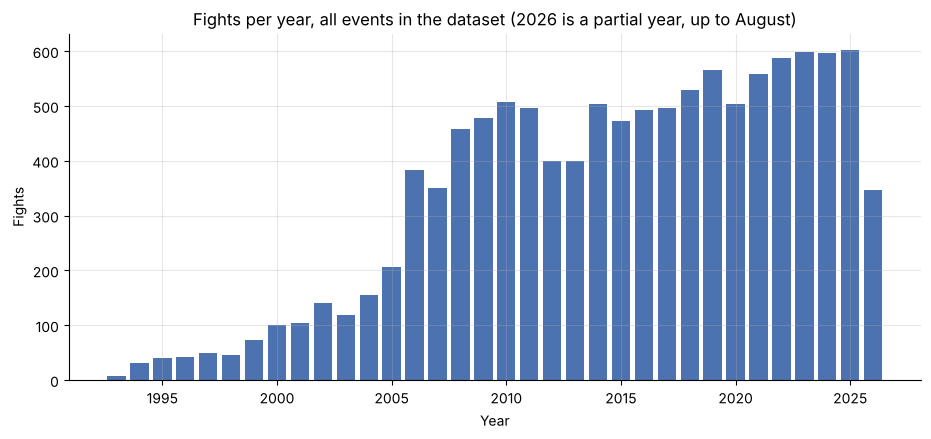

In [11]:
fights_per_year = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year, COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    GROUP BY year ORDER BY year
""")

fig, ax = plt.subplots()
ax.bar(fights_per_year["year"], fights_per_year["fights"], color="#4C72B0")
ax.set_title("Fights per year, all events in the dataset (2026 is a partial year, up to August)")
ax.set_xlabel("Year")
ax.set_ylabel("Fights")
plt.show()

**Observation.** The dataset has only a few dozen fights a year in the 1990s. Numbers grew quickly from 2005 and have been at roughly 500–600 a year since the mid-2010s. Most of the data comes from the modern era, which is the era the model needs to predict. Not every event is a UFC event: Section 4.9 shows the dataset also includes other promotions.

### 4.2 How fights end

In [12]:
query("""
    SELECT result_status, COUNT(*) AS fights,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM fight), 1) AS pct
    FROM fight GROUP BY result_status ORDER BY fights DESC
""")

,result_status,fights,pct
0,win,11238,98.2
1,no_contest,118,1.0
2,draw,85,0.7


In [13]:
query("""
    SELECT method, COUNT(*) AS fights,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM fight), 1) AS pct
    FROM fight GROUP BY method ORDER BY fights DESC
""")

,method,fights,pct
0,Decision - Unanimous,3860,33.7
1,KO/TKO,3715,32.5
2,Submission,2411,21.1
3,Decision - Split,1015,8.9
4,TKO - Doctor's Stoppage,152,1.3
5,Decision - Majority,117,1.0
6,Overturned,71,0.6
7,Could Not Continue,48,0.4
8,DQ,35,0.3
9,Other,14,0.1


**Observation.** 98% of fights have a winner. Draws and no-contests (fights that were overturned or stopped without a result, about 1.8% together) can't be used to train a winner-prediction model, so they will be excluded from the target. Among wins, decisions (judges' scores) are the most common outcome, followed by knockouts (KO/TKO) and submissions.

### 4.3 The changing sport: finish rate over time

A fight is *finished* if it ends early by knockout (KO/TKO) or submission, rather than going the distance to the judges. Comparing finish rates over time needs care, because the rules changed.

In [14]:
early_rules = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year,
           COUNT(*) AS fights,
           SUM(f.time_format = 'No Time Limit') AS no_time_limit,
           SUM(f.method LIKE 'Decision%') AS decisions,
           ROUND(100.0 * AVG(f.method IN ('KO/TKO', 'Submission', 'TKO - Doctor''s Stoppage')), 1) AS finish_pct
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win' AND e.event_date < ?
    GROUP BY year ORDER BY year
""", (MODERN_RULES_FROM,))
early_rules

,year,fights,no_time_limit,decisions,finish_pct
0,1993,8,8,0,100.0
1,1994,31,31,0,100.0
2,1995,38,0,3,92.1
3,1996,43,0,5,88.4
4,1997,46,0,8,82.6
5,1998,43,1,8,76.7
6,1999,70,1,21,68.6
7,2000,98,0,36,61.2


**Why the early finish rate is close to 100%.** This is not a data error. The first events (1993–1994) had **no time limit** (every fight in those years is `No Time Limit`), so there were no judges' decisions: every fight had to end with a knockout, a submission or a stoppage. Decisions only appear once time limits were introduced in 1995. Through the late 1990s, rules and round formats kept changing (one long round with overtime, two 10-minute rounds, and so on), and fighters often fought several times in one night in tournaments.

From about 2001, round-based formats with judges became the standard, so this analysis and the models only compare fights from **2001 onwards** (`MODERN_RULES_FROM`). Earlier fights are still kept in the database, because they are real results that count towards a fighter's history.

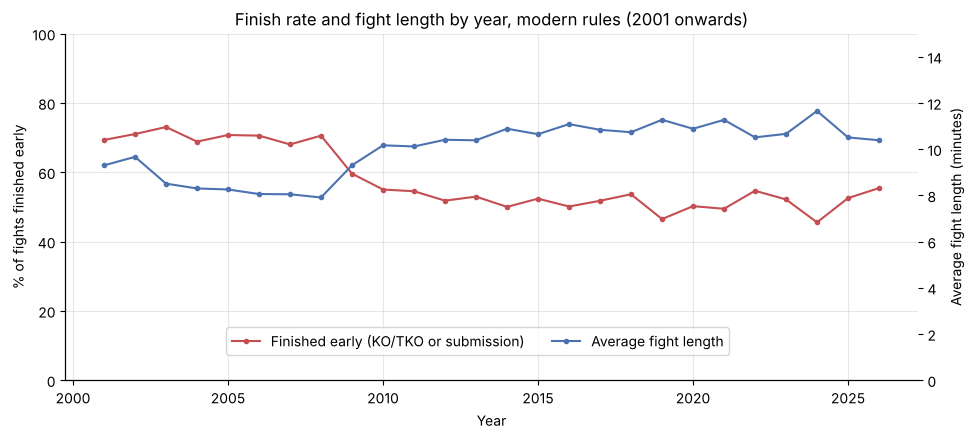

Finish rate 2001–2008: 70%
Finish rate 2010 onwards: 52%


In [15]:
finish_rate = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year,
           AVG(CASE WHEN f.method IN ('KO/TKO', 'Submission', 'TKO - Doctor''s Stoppage')
                    THEN 1.0 ELSE 0.0 END) AS finish_rate,
           AVG(f.duration_s) / 60.0 AS avg_minutes
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win' AND e.event_date >= ?
    GROUP BY year ORDER BY year
""", (MODERN_RULES_FROM,))

fig, ax1 = plt.subplots()
ax1.plot(finish_rate["year"], finish_rate["finish_rate"] * 100, color="#C44E52", marker="o", markersize=3,
         label="Finished early (KO/TKO or submission)")
ax1.set_ylim(0, 100)
ax1.set_ylabel("% of fights finished early")
ax1.set_xlabel("Year")
ax2 = ax1.twinx()
ax2.plot(finish_rate["year"], finish_rate["avg_minutes"], color="#4C72B0", marker="o", markersize=3,
         label="Average fight length")
ax2.set_ylim(0, 15)
ax2.set_ylabel("Average fight length (minutes)")
ax2.grid(False)
fig.legend(loc="lower center", bbox_to_anchor=(0.5, 0.15), ncol=2)
ax1.set_title("Finish rate and fight length by year, modern rules (2001 onwards)")
plt.show()

print(f"Finish rate 2001–2008: {finish_rate.query('year <= 2008')['finish_rate'].mean():.0%}")
print(f"Finish rate 2010 onwards: {finish_rate.query('year >= 2010')['finish_rate'].mean():.0%}")

**Observation.** Even under comparable rules, the sport has changed. From 2001 to 2008, roughly 70% of fights ended early. Since 2010 it has been about half, and the average fight has got longer, as more fights go the full distance to a decision. Part of the drop around 2009–2010 may come from the mix of events in the dataset changing at the same time (Section 4.9). Either way, a model trained mainly on older fights would learn patterns that no longer apply, which is another reason to train and test on fights from 2010 onwards.

### 4.4 Weight classes

In [16]:
weight_classes = query("""
    SELECT weight_class, COUNT(*) AS fights FROM fight
    GROUP BY weight_class ORDER BY fights DESC
""")
print(f"{len(weight_classes)} different weight-class labels")
print(f"Top 15 labels cover {weight_classes['fights'].head(15).sum() / weight_classes['fights'].sum():.1%} of fights")
weight_classes.head(15)

154 different weight-class labels
Top 15 labels cover 97.9% of fights


,weight_class,fights
0,Lightweight,1830
1,Welterweight,1693
2,Middleweight,1523
3,Featherweight,1101
4,Heavyweight,1087
5,Bantamweight,963
6,Light Heavyweight,938
7,Flyweight,495
8,Women's Strawweight,408
9,Open Weight,317


**Observation.** The `weight_class` field is messy. It contains the standard divisions (Lightweight, Welterweight and so on), but also labels like tournament names (*Ultimate Fighter 9 Welterweight Tournament*) and other promotions' titles (*WEC*, *Strikeforce*, *Pride*). The 15 most common labels cover almost all fights. The rest will be mapped to standard divisions by keyword in the feature-engineering part (for example, anything containing *Welterweight* becomes Welterweight).

### 4.5 Fighters

Fighters who appear in at least one fight: 4,124
Median UFC fights per fighter: 3 (maximum 50)
Fighters with only one UFC fight: 31%


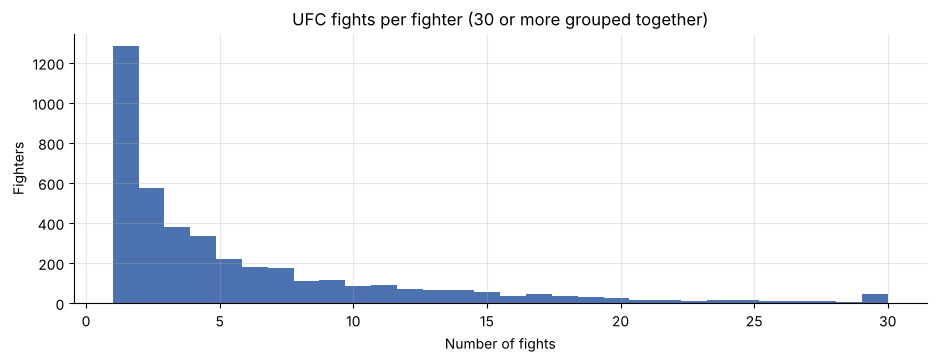

In [17]:
fights_per_fighter = query("""
    SELECT fighter_id, COUNT(*) AS fights FROM (
        SELECT r_id AS fighter_id FROM fight
        UNION ALL
        SELECT b_id AS fighter_id FROM fight
    ) GROUP BY fighter_id
""")["fights"]

print(f"Fighters who appear in at least one fight: {len(fights_per_fighter):,}")
print(f"Median UFC fights per fighter: {fights_per_fighter.median():.0f} (maximum {fights_per_fighter.max()})")
print(f"Fighters with only one UFC fight: {(fights_per_fighter == 1).mean():.0%}")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.hist(fights_per_fighter.clip(upper=30), bins=30, color="#4C72B0")
ax.set_title("UFC fights per fighter (30 or more grouped together)")
ax.set_xlabel("Number of fights")
ax.set_ylabel("Fighters")
plt.show()

In [18]:
fighter_missing = query("""
    SELECT COUNT(*) AS fighters,
           ROUND(100.0 * SUM(height_cm IS NULL) / COUNT(*), 1) AS pct_no_height,
           ROUND(100.0 * SUM(reach_cm IS NULL) / COUNT(*), 1)  AS pct_no_reach,
           ROUND(100.0 * SUM(dob IS NULL) / COUNT(*), 1)       AS pct_no_dob,
           ROUND(100.0 * SUM(stance IS NULL) / COUNT(*), 1)    AS pct_no_stance,
           SUM(slpm = 0 AND str_acc = 0 AND sapm = 0 AND str_def = 0
               AND td_avg = 0 AND td_acc = 0 AND td_def = 0 AND sub_avg = 0) AS all_stats_zero
    FROM fighter
""")
fighter_missing

,fighters,pct_no_height,pct_no_reach,pct_no_dob,pct_no_stance,all_stats_zero
0,4581,8.1,43.5,11.1,19.6,754


**Observation.** Fighter histories are short. The median fighter has only a few UFC fights, and almost a third have just one. Many fights will therefore involve at least one fighter with little or no UFC history, and the features in the next part must handle this (for example a "number of previous fights" feature, and sensible default values for debuts).

Physical details are often missing, especially **reach**, and some fighters have **every statistic set to exactly 0**. That isn't a real value, it's a placeholder for fighters with no recorded statistics, so it must be treated as missing.

### 4.6 The red-corner problem

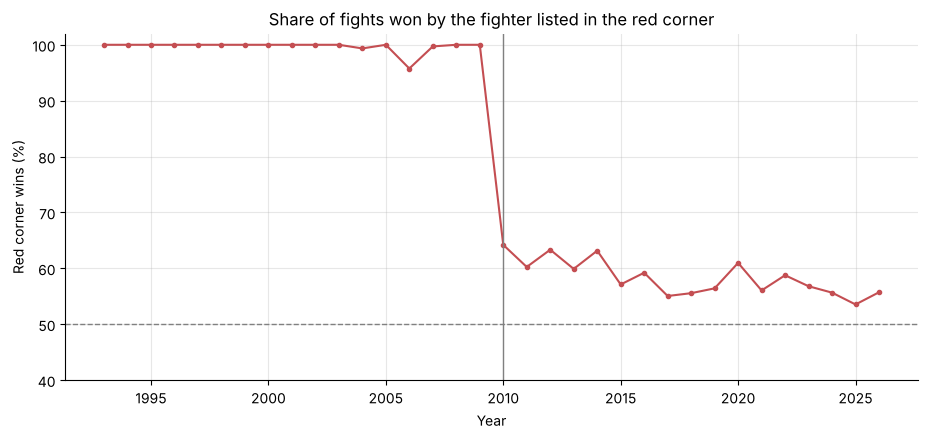

,red_win_rate,fights
year,,
2006,95.8%,377
2007,99.7%,344
2008,100.0%,455
2009,100.0%,475
2010,64.2%,500
2011,60.2%,488
2012,63.3%,390
2013,59.9%,389


In [19]:
red_wins = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year,
           AVG(CASE WHEN f.winner_id = f.r_id THEN 1.0 ELSE 0.0 END) AS red_win_rate,
           COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win'
    GROUP BY year ORDER BY year
""")

fig, ax = plt.subplots()
ax.plot(red_wins["year"], red_wins["red_win_rate"] * 100, color="#C44E52", marker="o", markersize=3)
ax.axhline(50, color="grey", linewidth=1, linestyle="--")
ax.axvline(2010, color="grey", linewidth=1)
ax.set_ylim(40, 102)
ax.set_title("Share of fights won by the fighter listed in the red corner")
ax.set_xlabel("Year")
ax.set_ylabel("Red corner wins (%)")
plt.show()

red_wins[(red_wins["year"] >= 2006) & (red_wins["year"] <= 2013)].set_index("year").style.format(
    {"red_win_rate": "{:.1%}"})

In [20]:
quarterly = query("""
    SELECT strftime('%Y', e.event_date) || '-Q' || ((CAST(strftime('%m', e.event_date) AS INTEGER) + 2) / 3) AS quarter,
           AVG(CASE WHEN f.winner_id = f.r_id THEN 1.0 ELSE 0.0 END) AS red_win_rate,
           COUNT(*) AS fights
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.result_status = 'win' AND e.event_date BETWEEN '2009-07-01' AND '2010-12-31'
    GROUP BY quarter ORDER BY quarter
""")
quarterly.style.format({"red_win_rate": "{:.1%}"})

,quarter,red_win_rate,fights
0,2009-Q3,100.0%,96
1,2009-Q4,100.0%,149
2,2010-Q1,90.2%,122
3,2010-Q2,52.4%,124
4,2010-Q3,62.4%,125
5,2010-Q4,52.7%,129


**Observation: an important data quality problem.** Up to the end of 2009, the fighter in the "red" column wins **almost every fight**. That isn't a real effect. In older records, ufcstats.com lists the **winner first**, and the scraper stored the first fighter as red. From around **April 2010** the red corner wins about 52–65% of fights, which is realistic (in the UFC the red corner usually goes to the favourite or the champion).

**Why this matters for the model.** If the model were given "which column is this fighter in?", it would learn "red wins" from the old fights. That would make it look very accurate on historical data while being useless for real predictions. This is a form of **data leakage**. To avoid it:

1. The model will not use corner colour from fights before April 2010 (`CORNER_RELIABLE_FROM`).
2. The fighters in each fight will be put in a **random order** (fighter A / fighter B) before modelling, so the column a fighter is in carries no information.
3. Fights before 2010 are still useful for building each fighter's **history** (record, Elo rating), because who won those fights is correct. Only the corner colour is unreliable.

### 4.7 Fight statistics: the leakage trap

In [21]:
example = query("""
    SELECT fr.name, COUNT(*) AS ufc_fights,
           MIN(e.event_date) AS first_fight, MAX(e.event_date) AS last_fight,
           fr.slpm AS strikes_landed_per_min, fr.str_acc AS striking_accuracy_pct
    FROM fighter fr
    JOIN fight f ON fr.fighter_id IN (f.r_id, f.b_id)
    JOIN event e ON e.event_id = f.event_id
    GROUP BY fr.fighter_id
    ORDER BY ufc_fights DESC
    LIMIT 5
""")
example

,name,ufc_fights,first_fight,last_fight,strikes_landed_per_min,striking_accuracy_pct
0,Alistair Overeem,50,2002-07-20,2021-02-06,3.67,64
1,Andrei Arlovski,48,2000-11-17,2024-06-29,3.82,45
2,Donald Cerrone,48,2007-09-05,2022-07-02,4.41,46
3,Jim Miller,47,2008-10-18,2026-05-09,2.92,42
4,Kazushi Sakuraba,44,1997-12-21,2011-09-24,1.26,41


**Observation.** The `fighter` table has **one row per fighter**, and the career statistics (strikes landed per minute, accuracy, takedowns and so on) were captured when the data was scraped in August 2026. For example, Alistair Overeem's figures cover all 50 of his fights from 2002 to 2021, including the ones a model would be asked to predict.

Using them to predict his 2012 fight would give the model information from 2013–2021. This is the main leakage trap in this dataset. In the next part, all fighter statistics will instead be **rebuilt from the `round` table using only fights that happened before the fight being predicted**.

### 4.8 Missing round statistics

In [22]:
missing_rounds = query("""
    SELECT CAST(strftime('%Y', e.event_date) AS INTEGER) AS year, COUNT(*) AS fights_without_round_stats
    FROM fight f JOIN event e ON e.event_id = f.event_id
    WHERE f.fight_id NOT IN (SELECT DISTINCT fight_id FROM round)
    GROUP BY year ORDER BY year
""")
print(f"Fights with no round statistics: {missing_rounds['fights_without_round_stats'].sum()}")
print("All of them are listed in scrape_error:",
      query("SELECT COUNT(*) AS n FROM fight WHERE fight_id NOT IN (SELECT fight_id FROM round) "
            "AND fight_id NOT IN (SELECT entity_id FROM scrape_error)")["n"][0] == 0)
missing_rounds.set_index("year").T

Fights with no round statistics: 330
All of them are listed in scrape_error: True


year,1994,1995,1996,1997,1998,2001,2002,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
fights_without_round_stats,2,6,7,2,4,8,17,1,1,18,22,43,63,60,73,1,2


In [23]:
master_zeroes = raw["master"].loc[
    ~raw["master"]["fight_id"].isin(raw["round"]["fight_id"]),
    ["r_total_sig_landed", "b_total_sig_landed", "r_total_ctrl_seconds"]
]
print("In master.csv, the same fights have these 'totals':")
master_zeroes.describe().loc[["count", "mean", "max"]]

In master.csv, the same fights have these 'totals':


,r_total_sig_landed,b_total_sig_landed,r_total_ctrl_seconds
count,330.0,330.0,330.0
mean,0.0,0.0,0.0
max,0.0,0.0,0.0


**Observation.** 330 fights, mostly from 2006–2011, have no round-by-round statistics on ufcstats.com. The scraper logged every one of them in `scrape_error`. The pre-joined `master.csv` file reports **0 strikes and 0 control time** for these fights instead of leaving them blank. Treating them as real zeros would make those fighters look like they never landed a strike. This is a second reason the database uses the normalised `round` table, where these fights simply have no rows. The feature-engineering part will skip them when computing statistics.

There are also some rounds with missing **control time** (`ctrl_s`), which wasn't recorded for some older fights.

### 4.9 Promotions in the dataset

The event names show that the dataset is not limited to UFC events. ufcstats.com also lists fights from other organisations whose records the UFC has acquired, and from UFC-run series. The promotion is taken from the event name: names containing "UFC" (including *UFC Fight Night* and *Noche UFC*) or starting with *The Ultimate Fighter* are UFC events, *DWCS* and *Road to UFC* are UFC-run series, and everything else is another promotion. (SQL `LIKE` ignores upper/lower case, so *Road To UFC* also matches.)

In [24]:
PROMOTION_SQL = """
    CASE
        WHEN event_name LIKE 'DWCS%' OR event_name LIKE 'Road to UFC%' THEN 'UFC series (DWCS / Road to UFC)'
        WHEN event_name LIKE '%UFC%' OR event_name LIKE 'The Ultimate Fighter%' THEN 'UFC'
        ELSE 'Other promotion'
    END
"""

promotions = query(f"""
    SELECT {PROMOTION_SQL} AS promotion,
           COUNT(DISTINCT e.event_id) AS events, COUNT(*) AS fights,
           MIN(e.event_date) AS first_event, MAX(e.event_date) AS last_event
    FROM fight f JOIN event e ON e.event_id = f.event_id
    GROUP BY promotion ORDER BY fights DESC
""")
promotions

,promotion,events,fights,first_event,last_event
0,UFC,783,8819,1993-11-12,2026-08-08
1,Other promotion,369,2044,1997-06-15,2013-07-13
2,UFC series (DWCS / Road to UFC),107,578,2017-07-11,2026-05-29


In [25]:
query("""
    SELECT CASE WHEN instr(event_name, ':') > 0 THEN substr(event_name, 1, instr(event_name, ':') - 1)
                ELSE substr(event_name, 1, instr(event_name || ' ', ' ') - 1) END AS name_prefix,
           COUNT(*) AS events, MIN(event_date) AS first_event, MAX(event_date) AS last_event
    FROM event
    WHERE event_name NOT LIKE '%UFC%' AND event_name NOT LIKE 'The Ultimate Fighter%'
      AND event_name NOT LIKE 'DWCS%'
    GROUP BY name_prefix ORDER BY events DESC LIMIT 10
""")

,name_prefix,events,first_event,last_event
0,Strikeforce,63,2006-03-10,2013-01-12
1,PRIDE,39,1997-10-11,2006-12-31
2,K-1,20,2001-08-19,2007-12-31
3,EliteXC,10,2007-02-10,2008-10-04
4,DREAM,10,2009-10-25,2012-12-31
5,Meca,8,2000-05-27,2003-08-01
6,IFL,8,2006-04-29,2008-05-16
7,Shooto,7,2001-03-02,2007-02-17
8,Sengoku,6,2008-03-05,2009-03-20
9,UCC,5,2002-01-25,2003-01-25


**Observation.** Most fights are from UFC events, but the dataset also includes the UFC's own development series (Dana White's Contender Series and Road to UFC) and older organisations such as PRIDE, Strikeforce, WEC and DREAM. The other promotions had all stopped by 2013.

**Decision.** All fights are kept. They are real professional results, and many fighters competed in these organisations before or after joining the UFC, so their results make fighter histories (records, Elo ratings) more complete. The **test set** (2024 onwards) contains only UFC events and UFC series, because the other promotions had stopped by then.

## 5. Data quality summary

In [26]:
def ufc_quality_report():
    """Summarise the data quality issues found in Section 4, using SQL counts."""
    n_fights = query("SELECT COUNT(*) AS n FROM fight")["n"][0]
    n_fighters = query("SELECT COUNT(*) AS n FROM fighter")["n"][0]
    issues = [
        ("Validity", "fight", "Red corner listed as winner by default (before Apr 2010)",
         query("SELECT COUNT(*) AS n FROM fight f JOIN event e ON e.event_id = f.event_id "
               "WHERE e.event_date < ?", (CORNER_RELIABLE_FROM,))["n"][0], n_fights,
         "Fixed: random fighter order, corner never used (Section 9.1)"),
        ("Timeliness", "fighter", "Career stats are a 2026 snapshot (leakage)", n_fighters, n_fighters,
         "Fixed: rebuilt from earlier fights only (Section 8)"),
        ("Completeness", "round", "Fights with no round statistics",
         query("SELECT COUNT(*) AS n FROM fight WHERE fight_id NOT IN (SELECT fight_id FROM round)")["n"][0],
         n_fights, "Fixed: left as missing, skipped in averages (Section 7.3)"),
        ("Completeness", "fighter", "Reach missing",
         query("SELECT COUNT(*) AS n FROM fighter WHERE reach_cm IS NULL")["n"][0], n_fighters,
         "Difference set to 0 when missing (Section 9.2)"),
        ("Completeness", "fighter", "Date of birth missing",
         query("SELECT COUNT(*) AS n FROM fighter WHERE dob IS NULL")["n"][0], n_fighters,
         "Difference set to 0 when missing (Section 9.2)"),
        ("Validity", "fighter", f"Date of birth gives an age outside {VALID_AGE[0]}–{VALID_AGE[1]} at a fight",
         len(query(f"SELECT DISTINCT fr.fighter_id FROM fighter fr JOIN fight f ON fr.fighter_id IN (f.r_id, f.b_id) "
                   f"JOIN event e ON e.event_id = f.event_id WHERE (julianday(e.event_date) - julianday(fr.dob)) / 365.25 "
                   f"NOT BETWEEN {VALID_AGE[0]} AND {VALID_AGE[1]}")), n_fighters,
         "Fixed: age treated as missing (Section 8.3)"),
        ("Validity", "fighter", "All statistics exactly 0 (placeholder)",
         int(fighter_missing["all_stats_zero"][0]), n_fighters, "Not used: statistics rebuilt from rounds (Section 8)"),
        ("Consistency", "fight", "Non-standard weight-class labels",
         int(weight_classes["fights"].iloc[15:].sum()), n_fights, "Fixed: mapped to standard divisions (Section 7.2)"),
        ("Consistency", "fight", "Early rules (no time limits, tournaments) before 2001",
         query("SELECT COUNT(*) AS n FROM fight f JOIN event e ON e.event_id = f.event_id "
               "WHERE e.event_date < ?", (MODERN_RULES_FROM,))["n"][0], n_fights,
         "Kept for fighter history only, not modelled (Section 4.3)"),
        ("Relevance", "event", "Fights from other promotions",
         int(promotions.loc[promotions["promotion"] == "Other promotion", "fights"].sum()), n_fights,
         "Kept for fighter history (Section 4.9)"),
        ("Relevance", "fight", "Draws and no-contests (no winner)",
         query("SELECT COUNT(*) AS n FROM fight WHERE result_status != 'win'")["n"][0], n_fights,
         "Exclude from the target"),
    ]
    report = pd.DataFrame(issues, columns=["dimension", "table", "issue", "records", "of", "action"])
    report["%"] = report["records"] / report["of"]
    return report.drop(columns="of")


ufc_quality_report().style.format({"records": "{:,}", "%": "{:.1%}"})

,dimension,table,issue,records,action,%
0,Validity,fight,Red corner listed as winner by default (before Apr 2010),"2,911","Fixed: random fighter order, corner never used (Section 9.1)",25.4%
1,Timeliness,fighter,Career stats are a 2026 snapshot (leakage),"4,581",Fixed: rebuilt from earlier fights only (Section 8),100.0%
2,Completeness,round,Fights with no round statistics,330,"Fixed: left as missing, skipped in averages (Section 7.3)",2.9%
3,Completeness,fighter,Reach missing,"1,992",Difference set to 0 when missing (Section 9.2),43.5%
4,Completeness,fighter,Date of birth missing,510,Difference set to 0 when missing (Section 9.2),11.1%
5,Validity,fighter,Date of birth gives an age outside 16–55 at a fight,1,Fixed: age treated as missing (Section 8.3),0.0%
6,Validity,fighter,All statistics exactly 0 (placeholder),754,Not used: statistics rebuilt from rounds (Section 8),16.5%
7,Consistency,fight,Non-standard weight-class labels,242,Fixed: mapped to standard divisions (Section 7.2),2.1%
8,Consistency,fight,"Early rules (no time limits, tournaments) before 2001",390,"Kept for fighter history only, not modelled (Section 4.3)",3.4%
9,Relevance,event,Fights from other promotions,"2,044",Kept for fighter history (Section 4.9),17.9%


## 6. Provenance, licence and ethics

**Provenance.** The data was scraped from ufcstats.com, the UFC's official statistics site. The `scrape_error` table shows the scrape ran on 11 August 2026, so the data covers events up to 8 August 2026. It was downloaded from Kaggle as a zip of CSV files.

**Licence.** *[To complete: add the Kaggle dataset's author, URL and licence before final submission.]* The underlying statistics belong to the UFC. This analysis is for non-commercial, educational use only.

**Ethics.**

- **Real people.** The data describes real, named athletes. Their records and fight statistics are public, published by the UFC itself. Dates of birth are personal data, so they are used only to calculate age at the time of a fight and are never shown individually.
- **Scraping.** Collecting data by scraping should respect a site's terms of use and avoid overloading it. This project uses an existing scraped copy and doesn't scrape the site again.
- **Use of predictions.** Fight predictions are closely linked to betting. This model is an academic exercise. It is not intended or validated for betting, and its limitations will be stated clearly in the conclusion.

## 7. Data preparation

### 7.1 A combined view of each fight

Most later steps need the fight together with its event date and a few derived columns. These are defined once, as a SQL **view**: a saved query that behaves like a table but always reflects the underlying data.

- `promotion`, from the event name (Section 4.9)
- `modern_rules`: 1 for fights from 2001 onwards (Section 4.3)
- `corner_reliable`: 1 for fights from April 2010 onwards (Section 4.6)
- `division`: a standard weight class (Section 7.2)

In [27]:
DIVISION_SQL = """
    CASE
        WHEN weight_class LIKE '%Women%Strawweight%' OR weight_class LIKE '%Women%Atomweight%' THEN 'Women''s Strawweight'
        WHEN weight_class LIKE '%Women%Flyweight%'      THEN 'Women''s Flyweight'
        WHEN weight_class LIKE '%Women%Bantamweight%' OR weight_class LIKE '%Women''s 135%' THEN 'Women''s Bantamweight'
        WHEN weight_class LIKE '%Women%Featherweight%' OR weight_class LIKE '%Women''s 145%' THEN 'Women''s Featherweight'
        WHEN weight_class LIKE '%Light Heavyweight%'    THEN 'Light Heavyweight'
        WHEN weight_class LIKE '%Super Heavyweight%' OR weight_class LIKE '%Heavyweight%' THEN 'Heavyweight'
        WHEN weight_class LIKE '%Middleweight%'         THEN 'Middleweight'
        WHEN weight_class LIKE '%Welterweight%'         THEN 'Welterweight'
        WHEN weight_class LIKE '%Lightweight%'          THEN 'Lightweight'
        WHEN weight_class LIKE '%Featherweight%'        THEN 'Featherweight'
        WHEN weight_class LIKE '%Bantamweight%'         THEN 'Bantamweight'
        WHEN weight_class LIKE '%Flyweight%'            THEN 'Flyweight'
        ELSE 'Other (open / catch weight / unknown)'
    END
"""

conn.execute("DROP VIEW IF EXISTS fight_info")
conn.execute(f"""
    CREATE VIEW fight_info AS
    SELECT f.*,
           e.event_name,
           e.event_date,
           {PROMOTION_SQL}                                      AS promotion,
           CASE WHEN e.event_date >= '{MODERN_RULES_FROM}' THEN 1 ELSE 0 END    AS modern_rules,
           CASE WHEN e.event_date >= '{CORNER_RELIABLE_FROM}' THEN 1 ELSE 0 END AS corner_reliable,
           {DIVISION_SQL}                                       AS division
    FROM fight f
    JOIN event e ON e.event_id = f.event_id
""")
query("SELECT fight_id, event_date, promotion, modern_rules, corner_reliable, weight_class, division "
      "FROM fight_info ORDER BY event_date DESC LIMIT 5")

,fight_id,event_date,promotion,modern_rules,corner_reliable,weight_class,division
0,1168a8e59aacfd72,2026-08-08,UFC,1,1,Featherweight,Featherweight
1,d463229133909215,2026-08-08,UFC,1,1,Women's Flyweight,Women's Flyweight
2,f44ab9e9e4a89735,2026-08-08,UFC,1,1,Welterweight,Welterweight
3,81ae2a465e0dfa4f,2026-08-08,UFC,1,1,Lightweight,Lightweight
4,64829a32c78ab656,2026-08-08,UFC,1,1,Heavyweight,Heavyweight


### 7.2 Standard weight classes

In [28]:
query("""
    SELECT division, COUNT(*) AS fights, COUNT(DISTINCT weight_class) AS original_labels
    FROM fight_info GROUP BY division ORDER BY fights DESC
""")

,division,fights,original_labels
0,Lightweight,1871,22
1,Welterweight,1722,21
2,Middleweight,1559,23
3,Featherweight,1128,14
4,Heavyweight,1114,17
5,Bantamweight,982,11
6,Light Heavyweight,958,10
7,Other (open / catch weight / unknown),574,18
8,Flyweight,500,6
9,Women's Strawweight,414,4


**Observation.** The 154 original labels map onto 12 standard divisions plus an "Other" group (open weight, catch weight and labels with no division in the name). Division isn't used directly as a feature, because both fighters are always in the same division, so it can't tell them apart. It is used to check results by division.

### 7.3 One row per fighter per fight

To build a fighter's history, each fight is turned into **two rows**, one from each fighter's point of view: their result, and the statistics they produced and conceded. Round statistics are summed per fight. If a fight has no round data, its statistics stay **NULL** (missing), never 0 (Section 4.8). Control time is only counted when every round of the fight has it.

The SQL for the red and blue sides is the same with `r_` and `b_` swapped, so it is generated by a function.

In [29]:
ROUND_TOTALS_SQL = """
    SELECT fight_id,
           SUM(r_sig_landed) AS r_sig_landed, SUM(r_sig_atmp) AS r_sig_atmp,
           SUM(b_sig_landed) AS b_sig_landed, SUM(b_sig_atmp) AS b_sig_atmp,
           SUM(r_td_success) AS r_td, SUM(r_td_atmp) AS r_td_atmp,
           SUM(b_td_success) AS b_td, SUM(b_td_atmp) AS b_td_atmp,
           SUM(r_kd) AS r_kd, SUM(b_kd) AS b_kd,
           SUM(r_sub_att) AS r_sub_att, SUM(b_sub_att) AS b_sub_att,
           CASE WHEN COUNT(r_ctrl_s) = COUNT(*) THEN SUM(r_ctrl_s) END AS r_ctrl_s,
           CASE WHEN COUNT(b_ctrl_s) = COUNT(*) THEN SUM(b_ctrl_s) END AS b_ctrl_s
    FROM round GROUP BY fight_id
"""


def side_sql(me, opp):
    """SELECT for one fighter's view of each fight (me = 'r' or 'b')."""
    return f"""
    SELECT fi.fight_id, fi.event_date, fi.{me}_id AS fighter_id, fi.{opp}_id AS opponent_id,
           CASE WHEN fi.result_status = 'win' AND fi.winner_id = fi.{me}_id  THEN 1 ELSE 0 END AS win,
           CASE WHEN fi.result_status = 'win' AND fi.winner_id = fi.{opp}_id THEN 1 ELSE 0 END AS loss,
           CASE WHEN fi.result_status = 'draw' THEN 1 ELSE 0 END AS draw,
           CASE WHEN fi.method IN ('KO/TKO', 'Submission', 'TKO - Doctor''s Stoppage') THEN 1 ELSE 0 END AS finish,
           CASE WHEN rt.fight_id IS NOT NULL THEN fi.duration_s / 60.0 END AS minutes,
           rt.{me}_sig_landed AS sig_landed, rt.{me}_sig_atmp AS sig_atmp,
           rt.{opp}_sig_landed AS sig_absorbed, rt.{opp}_sig_atmp AS opp_sig_atmp,
           rt.{me}_td AS td, rt.{me}_td_atmp AS td_atmp,
           rt.{opp}_td AS opp_td, rt.{opp}_td_atmp AS opp_td_atmp,
           rt.{me}_kd AS kd, rt.{me}_sub_att AS sub_att, rt.{me}_ctrl_s AS ctrl_s
    FROM fight_info fi
    LEFT JOIN round_totals rt ON rt.fight_id = fi.fight_id
    """


fighter_fights = query(f"""
    WITH round_totals AS ({ROUND_TOTALS_SQL})
    SELECT * FROM (
        {side_sql('r', 'b')}
        UNION ALL
        {side_sql('b', 'r')}
    )
    ORDER BY event_date, fight_id
""")
fighter_fights["event_date"] = pd.to_datetime(fighter_fights["event_date"])

# A fight's statistics only count if its length is known, so rates per minute stay consistent.
STAT_COLUMNS = ["sig_landed", "sig_atmp", "sig_absorbed", "opp_sig_atmp", "td", "td_atmp",
                "opp_td", "opp_td_atmp", "kd", "sub_att", "ctrl_s"]
fighter_fights.loc[fighter_fights["minutes"].isna(), STAT_COLUMNS] = np.nan

print(f"{len(fighter_fights):,} rows (2 per fight); "
      f"{fighter_fights['minutes'].isna().mean():.1%} have no usable statistics")
fighter_fights.head()

22,882 rows (2 per fight); 2.9% have no usable statistics


,fight_id,event_date,fighter_id,opponent_id,win,loss,draw,finish,minutes,sig_landed,sig_atmp,sig_absorbed,opp_sig_atmp,td,td_atmp,opp_td,opp_td_atmp,kd,sub_att,ctrl_s
0,00b0796724ec1c09,1993-11-12,6ceff86fae4f6b3b,02fc8f50f56eb307,1,0,0,1,0.866667,3.0,9.0,1.0,7.0,1.0,2.0,0.0,0.0,0.0,1.0,NaN
1,00b0796724ec1c09,1993-11-12,02fc8f50f56eb307,6ceff86fae4f6b3b,0,1,0,1,0.866667,1.0,7.0,3.0,9.0,0.0,0.0,1.0,2.0,0.0,0.0,NaN
2,2d2bbc86e941e05c,1993-11-12,598a58db87b890ee,d3711d3784b76255,1,0,0,1,4.333333,15.0,27.0,12.0,28.0,0.0,0.0,0.0,0.0,2.0,0.0,NaN
3,2d2bbc86e941e05c,1993-11-12,d3711d3784b76255,598a58db87b890ee,0,1,0,1,4.333333,12.0,28.0,15.0,27.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
4,46acd54cc0c905fb,1993-11-12,63b65af1c5cb02cb,46c8ec317aff28ac,1,0,0,1,1.816667,1.0,1.0,4.0,8.0,1.0,2.0,0.0,0.0,0.0,2.0,NaN


## 8. Feature engineering

### 8.1 The no-leakage rule

Every feature for a fight on date *d* is calculated **only from fights on dates before *d***. Fights on the same day don't count, not even ones earlier on the same card. In the early tournaments a fighter could fight several times in one night, and the data doesn't record the order of fights within an event. A date-based rule is the only safe one.

The method:

1. Add up each fighter's results and statistics per **date**.
2. Take a running total over dates, then **shift it by one date**, so each date only sees the totals from before it.
3. Join these "before this date" totals back onto every fight.

In [30]:
SUM_COLUMNS = ["win", "loss", "draw", "minutes"] + STAT_COLUMNS


def history_before_each_date(fights):
    """Each fighter's totals from all fights on earlier dates, for every date they fought."""
    df = fights.copy()
    df["fights"] = 1
    df["finish_win"] = df["win"] * df["finish"]
    df["finish_loss"] = df["loss"] * df["finish"]
    columns = ["fights", "finish_win", "finish_loss"] + SUM_COLUMNS

    per_date = (df.groupby(["fighter_id", "event_date"])[columns]
                  .sum(min_count=1)
                  .reset_index()
                  .sort_values(["fighter_id", "event_date"]))
    running = per_date.groupby("fighter_id")[columns].transform(
        lambda col: col.fillna(0).cumsum().shift(1, fill_value=0))
    history = per_date[["fighter_id", "event_date"]].join(running.add_prefix("prev_"))
    history["prev_date"] = per_date.groupby("fighter_id")["event_date"].shift(1)

    # Current streak before each date: +n for n wins in a row, -n for n losses in a row
    streaks = []
    for _, fighter in per_date.groupby("fighter_id", sort=False):
        streak = 0
        for wins, losses in zip(fighter["win"].fillna(0), fighter["loss"].fillna(0)):
            streaks.append(streak)
            if wins > losses:
                streak = streak + 1 if streak > 0 else 1
            elif losses > wins:
                streak = streak - 1 if streak < 0 else -1
    history["prev_streak"] = streaks
    return history


history = history_before_each_date(fighter_fights)
history.head()

,fighter_id,event_date,prev_fights,prev_finish_win,prev_finish_loss,prev_win,prev_loss,prev_draw,prev_minutes,prev_sig_landed,...,prev_opp_sig_atmp,prev_td,prev_td_atmp,prev_opp_td,prev_opp_td_atmp,prev_kd,prev_sub_att,prev_ctrl_s,prev_date,prev_streak
0,000774e57404d8c7,2026-05-28,0,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaT,0
1,001eb2ab0f30e7ea,2025-06-07,0,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaT,0
2,002ca196477ce572,2019-07-20,0,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaT,0
3,002ca196477ce572,2020-02-29,1,0,0,0,1,0,15.0,8.0,...,23.0,1.0,6.0,6.0,9.0,0.0,0.0,266.0,2019-07-20,-1
4,003d82fa384ca1d0,2019-07-30,0,0,0,0,0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaT,0


**Checking the rule on a real fighter.** The cell below takes the fighter with the most fights and shows his record as the features see it before each of his first few fights: 0 fights before his debut, then one more after each date.

In [31]:
most_active = fighter_fights["fighter_id"].value_counts().index[0]
name = query("SELECT name FROM fighter WHERE fighter_id = ?", (most_active,))["name"][0]
own_fights = fighter_fights.loc[fighter_fights["fighter_id"] == most_active, ["event_date", "win", "loss"]]
own_history = history[history["fighter_id"] == most_active]
check = own_fights.merge(own_history, on="event_date")[
    ["event_date", "win", "loss", "prev_fights", "prev_win", "prev_loss", "prev_streak"]]
print(name)
check.head(6)

Alistair Overeem


,event_date,win,loss,prev_fights,prev_win,prev_loss,prev_streak
0,2002-07-20,1,0,0,0,0,0
1,2002-12-23,1,0,1,1,0,1
2,2003-06-08,1,0,2,2,0,2
3,2003-08-10,0,1,3,3,0,3
4,2003-12-31,1,0,4,3,1,-1
5,2004-10-31,1,0,5,4,1,1


### 8.2 Elo rating

The **Elo rating** system, first used in chess, gives every fighter a number that summarises the quality of their results. Everyone starts at 1500. Before a fight, the expected score of fighter A against B is:

$$E_A = \frac{1}{1 + 10^{(R_B - R_A)/400}}$$

After the fight, A's rating changes by $K \times (S_A - E_A)$, where $S_A$ is 1 for a win, 0.5 for a draw and 0 for a loss. Beating a much stronger opponent earns many points, and beating a weaker one earns few. No-contests don't change ratings.

Ratings are updated **date by date**: all fights on a date use the ratings from before that date (the rule from Section 8.1). Ratings are built from every fight in the dataset, starting in 1993, so fighters already have a meaningful rating by 2010.

In [32]:
def pre_fight_elo(fights, k):
    """Each fighter's Elo rating going into every fight, updated after each date."""
    ratings, before = {}, {}
    for _, day in fights.sort_values("event_date").groupby("event_date", sort=True):
        snapshot = {}
        for fight in day.itertuples():
            for fighter in (fight.r_id, fight.b_id):
                snapshot[fighter] = ratings.get(fighter, ELO_START)
            before[(fight.fight_id, fight.r_id)] = snapshot[fight.r_id]
            before[(fight.fight_id, fight.b_id)] = snapshot[fight.b_id]
        for fight in day.itertuples():
            if fight.result_status == "no_contest":
                continue
            expected_r = 1 / (1 + 10 ** ((snapshot[fight.b_id] - snapshot[fight.r_id]) / 400))
            score_r = 0.5 if fight.result_status == "draw" else float(fight.winner_id == fight.r_id)
            ratings[fight.r_id] = ratings.get(fight.r_id, ELO_START) + k * (score_r - expected_r)
            ratings[fight.b_id] = ratings.get(fight.b_id, ELO_START) + k * ((1 - score_r) - (1 - expected_r))
    return before, ratings


fights = query("SELECT fight_id, event_date, r_id, b_id, winner_id, result_status FROM fight_info")
fights["event_date"] = pd.to_datetime(fights["event_date"])

**Choosing K.** K controls how fast ratings react to new results. It is chosen using only the **training period** (April 2010 to December 2023): for each candidate value, how often did the fighter with the higher rating win? The test period is not used.

In [33]:
train_fights = fights[(fights["result_status"] == "win")
                      & (fights["event_date"] >= MODEL_FROM) & (fights["event_date"] < TEST_START)]


def elo_pick_accuracy(before, sample):
    """Share of fights won by the higher-rated fighter (equal ratings skipped)."""
    r = np.array([before[(f, a)] for f, a in zip(sample["fight_id"], sample["r_id"])])
    b = np.array([before[(f, c)] for f, c in zip(sample["fight_id"], sample["b_id"])])
    decided = r != b
    red_won = (sample["winner_id"] == sample["r_id"]).to_numpy()
    return ((r > b) == red_won)[decided].mean()


k_results = {}
for k in ELO_K_OPTIONS:
    before, _ = pre_fight_elo(fights, k)
    k_results[k] = elo_pick_accuracy(before, train_fights)

ELO_K = max(k_results, key=k_results.get)
print(pd.Series(k_results, name="higher Elo wins (training period)").map("{:.1%}".format).to_string())
print(f"Chosen K = {ELO_K}")
elo_before, elo_now = pre_fight_elo(fights, ELO_K)

16     56.5%
32     56.5%
64     56.8%
100    57.0%
150    57.7%
200    57.9%
300    57.5%
Chosen K = 200


In [34]:
latest = (pd.Series(elo_now, name="elo").rename_axis("fighter_id").reset_index()
          .merge(query("SELECT fighter_id, name FROM fighter"), on="fighter_id"))
last_fight = fighter_fights.groupby("fighter_id")["event_date"].max()
latest["last_fight"] = latest["fighter_id"].map(last_fight)
(latest[latest["last_fight"] >= "2024-01-01"]
 .sort_values("elo", ascending=False).head(10)[["name", "elo", "last_fight"]]
 .style.format({"elo": "{:.0f}", "last_fight": "{:%Y-%m-%d}"}).hide(axis="index"))

name,elo,last_fight
Jon Jones,2710,2024-11-16
Islam Makhachev,2708,2025-11-15
Justin Gaethje,2519,2026-06-14
Ciryl Gane,2494,2026-06-14
Dricus Du Plessis,2457,2026-07-18
Sean Strickland,2453,2026-05-09
Charles Oliveira,2442,2026-03-07
Stipe Miocic,2418,2024-11-16
Petr Yan,2404,2025-12-06
Movsar Evloev,2384,2026-03-21


**Sanity check.** The fighters with the highest ratings as of August 2026, among those active since 2024, are shown above. The list is led by long-time champions such as Jon Jones and Islam Makhachev, which suggests the ratings capture fighter quality sensibly.

### 8.3 Turning history into features

The running totals are turned into rates, so that fighters with long and short careers can be compared:

| Feature | Meaning |
|---|---|
| `elo` | Elo rating before the fight |
| `n_fights` | Previous fights in the dataset |
| `win_rate` | (wins + 1) / (fights + 2). The +1 and +2 stop a 1–0 fighter from scoring 100% |
| `streak` | Current win streak (positive) or losing streak (negative) |
| `finish_win_rate` | Share of previous wins by KO/TKO or submission |
| `finished_rate` | Share of previous fights lost by KO/TKO or submission |
| `days_since_last` | Days since the previous fight (ring rust or injury layoffs) |
| `slpm`, `sapm` | Significant strikes landed / absorbed per minute |
| `str_acc`, `str_def` | Share of own strikes that land, and of opponents' strikes avoided |
| `td_per15`, `td_def` | Takedowns per 15 minutes, and share of opponents' takedowns stopped |
| `ctrl_share` | Share of fight time spent in control of the opponent |
| `kd_per15`, `sub_per15` | Knockdowns and submission attempts per 15 minutes |
| `height_cm`, `reach_cm`, `age` | Physical attributes, with age calculated at the fight date |

Two safeguards: per-minute rates are only calculated once a fighter has at least 5 minutes of recorded fight time (`MIN_STAT_MINUTES`), because a fighter whose only fight lasted 20 seconds would otherwise get extreme values such as 100+ knockdowns per 15 minutes. Ages outside 16–55 (`VALID_AGE`) are treated as missing, because they come from wrong dates of birth (one fighter would be 4 years old).

In [35]:
def fighter_features(fighter_fights, history, elo_before):
    """Pre-fight features for every fighter in every fight."""
    X = fighter_fights[["fight_id", "fighter_id", "event_date"]].merge(
        history, on=["fighter_id", "event_date"], how="left")
    X["elo"] = [elo_before[(f, a)] for f, a in zip(X["fight_id"], X["fighter_id"])]

    n = X["prev_fights"]
    minutes = X["prev_minutes"].where(X["prev_minutes"] >= MIN_STAT_MINUTES)  # too little data -> missing
    X["n_fights"] = n
    X["win_rate"] = (X["prev_win"] + 1) / (n + 2)
    X["streak"] = X["prev_streak"]
    X["finish_win_rate"] = X["prev_finish_win"] / X["prev_win"].where(X["prev_win"] > 0)
    X["finished_rate"] = X["prev_finish_loss"] / n.where(n > 0)
    X["days_since_last"] = (X["event_date"] - X["prev_date"]).dt.days
    X["slpm"] = X["prev_sig_landed"] / minutes
    X["sapm"] = X["prev_sig_absorbed"] / minutes
    X["str_acc"] = X["prev_sig_landed"] / X["prev_sig_atmp"].where(X["prev_sig_atmp"] > 0)
    X["str_def"] = 1 - X["prev_sig_absorbed"] / X["prev_opp_sig_atmp"].where(X["prev_opp_sig_atmp"] > 0)
    X["td_per15"] = X["prev_td"] / minutes * 15
    X["td_def"] = 1 - X["prev_opp_td"] / X["prev_opp_td_atmp"].where(X["prev_opp_td_atmp"] > 0)
    X["ctrl_share"] = X["prev_ctrl_s"] / 60 / minutes
    X["kd_per15"] = X["prev_kd"] / minutes * 15
    X["sub_per15"] = X["prev_sub_att"] / minutes * 15

    physical = query("SELECT fighter_id, height_cm, reach_cm, dob FROM fighter").set_index("fighter_id")
    X["height_cm"] = X["fighter_id"].map(physical["height_cm"])
    X["reach_cm"] = X["fighter_id"].map(physical["reach_cm"])
    age = (X["event_date"] - pd.to_datetime(X["fighter_id"].map(physical["dob"]))).dt.days / 365.25
    X["age"] = age.where(age.between(*VALID_AGE))                            # impossible ages -> missing
    return X


FEATURES = ["elo", "n_fights", "win_rate", "streak", "finish_win_rate", "finished_rate", "days_since_last",
            "slpm", "sapm", "str_acc", "str_def", "td_per15", "td_def", "ctrl_share", "kd_per15", "sub_per15",
            "height_cm", "reach_cm", "age"]

features = fighter_features(fighter_fights, history, elo_before)
features[FEATURES].describe().T[["count", "mean", "min", "max"]].style.format("{:,.2f}")

,count,mean,min,max
elo,"22,882.00","1,650.86","1,165.56","2,667.80"
n_fights,"22,882.00",5.98,0.00,49.00
win_rate,"22,882.00",0.57,0.12,0.94
streak,"22,882.00",0.55,-7.00,20.00
finish_win_rate,"16,817.00",0.59,0.00,1.00
finished_rate,"18,703.00",0.19,0.00,1.00
days_since_last,"18,703.00",227.72,1.00,"3,906.00"
slpm,"17,356.00",3.42,0.00,20.55
sapm,"17,356.00",2.96,0.00,20.55
str_acc,"18,478.00",0.47,0.00,1.00


**Physical attributes.** Height and reach come from the `fighter` table, which is a 2026 snapshot. Unlike career statistics, an adult fighter's height and reach don't change, so using them is not leakage. Date of birth is only used to work out age on the fight date.

## 9. Modelling

### 9.1 Fixing the red-corner problem

As Section 4.6 showed, corner colour can't be trusted before April 2010, and even afterwards it partly reflects the promoter's opinion of who is the favourite. The model must not use it. Two steps remove it completely:

1. **Only fights from April 2010** onwards are used for training and testing (`MODEL_FROM`).
2. For every fight, a **random draw** decides which fighter becomes "fighter A" and which becomes "fighter B". The target is *did fighter A win?*. The corner columns are dropped and never reach the model.

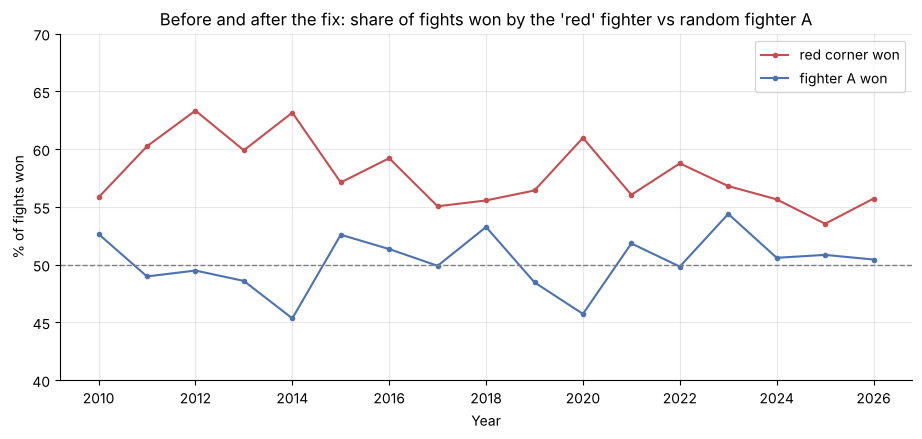

8,375 fights; fighter A won 50.3% overall


In [36]:
bouts = query("""
    SELECT fight_id, event_date, promotion, division, title_fight, r_id, b_id, winner_id
    FROM fight_info
    WHERE result_status = 'win' AND event_date >= ?
    ORDER BY event_date, fight_id
""", (MODEL_FROM,))
bouts["event_date"] = pd.to_datetime(bouts["event_date"])

rng = np.random.default_rng(RANDOM_SEED)
swap = rng.random(len(bouts)) < 0.5
bouts["a_id"] = np.where(swap, bouts["b_id"], bouts["r_id"])
bouts["b_id_"] = np.where(swap, bouts["r_id"], bouts["b_id"])
bouts["a_won"] = (bouts["winner_id"] == bouts["a_id"]).astype(int)
red_won = (bouts["winner_id"] == bouts["r_id"])
bouts = bouts.drop(columns=["r_id", "b_id"]).rename(columns={"b_id_": "b_id"})

by_year = pd.DataFrame({"red corner won": red_won.groupby(bouts["event_date"].dt.year).mean(),
                        "fighter A won": bouts.groupby(bouts["event_date"].dt.year)["a_won"].mean()})
fig, ax = plt.subplots()
by_year.mul(100).plot(ax=ax, marker="o", markersize=3, color=["#C44E52", "#4C72B0"])
ax.axhline(50, color="grey", linestyle="--", linewidth=1)
ax.set_ylim(40, 70)
ax.set_title("Before and after the fix: share of fights won by the 'red' fighter vs random fighter A")
ax.set_xlabel("Year")
ax.set_ylabel("% of fights won")
plt.show()
print(f"{len(bouts):,} fights; fighter A won {bouts['a_won'].mean():.1%} overall")

**Observation.** In the original data, the red corner wins more than half of the fights in every year, and up to 63% in some years. After the random assignment, fighter A's share moves randomly around 50%, roughly between 45% and 55% (normal chance variation with a few hundred fights a year), and is 50.3% overall. The column a fighter appears in no longer says anything about who won, so the model can only learn from the fighters themselves.

### 9.2 The modelling table

Each feature becomes a **difference**: fighter A's value minus fighter B's. A positive `elo` difference means A has the higher rating. Differences keep the model symmetric, because swapping A and B just flips the sign.

**Missing values.** Debutants have no previous fights, so their statistics are missing, as are some heights, reaches and ages. A missing difference is set to 0 ("no known difference"), and two flags, `a_debut` and `b_debut`, tell the model when a fighter has no history.

In [37]:
X_all = features.set_index(["fight_id", "fighter_id"])[FEATURES]
A = X_all.loc[list(zip(bouts["fight_id"], bouts["a_id"]))].reset_index(drop=True)
B = X_all.loc[list(zip(bouts["fight_id"], bouts["b_id"]))].reset_index(drop=True)

diffs = (A - B).add_prefix("diff_")
model_data = pd.concat([bouts.reset_index(drop=True), diffs], axis=1)
model_data["a_debut"] = (A["n_fights"] == 0).astype(float)
model_data["b_debut"] = (B["n_fights"] == 0).astype(float)

print("Share of missing values per difference (before filling):")
print(diffs.isna().mean().map("{:.0%}".format).to_string())

DIFF_COLUMNS = list(diffs.columns)
MODEL_COLUMNS = DIFF_COLUMNS + ["a_debut", "b_debut"]
model_data[DIFF_COLUMNS] = model_data[DIFF_COLUMNS].fillna(0)

Share of missing values per difference (before filling):
diff_elo                 0%
diff_n_fights            0%
diff_win_rate            0%
diff_streak              0%
diff_finish_win_rate    33%
diff_finished_rate      22%
diff_days_since_last    22%
diff_slpm               29%
diff_sapm               29%
diff_str_acc            23%
diff_str_def            23%
diff_td_per15           29%
diff_td_def             32%
diff_ctrl_share         29%
diff_kd_per15           29%
diff_sub_per15          29%
diff_height_cm           1%
diff_reach_cm            9%
diff_age                 1%


### 9.3 Train/test split

As in Project 1, the split is **by time**: the model is trained on fights up to the end of 2023 and tested on 2024 onwards, the same way it would be used in practice.

In [38]:
train = model_data[model_data["event_date"] < TEST_START]
test = model_data[model_data["event_date"] >= TEST_START]
X_train, y_train = train[MODEL_COLUMNS], train["a_won"]
X_test, y_test = test[MODEL_COLUMNS], test["a_won"]

print(f"Training: {len(train):,} fights ({train['event_date'].min():%b %Y} – {train['event_date'].max():%b %Y})")
print(f"Test:     {len(test):,} fights ({test['event_date'].min():%b %Y} – {test['event_date'].max():%b %Y})")
print("Test promotions:", test["promotion"].value_counts().to_dict())

Training: 6,847 fights (Apr 2010 – Dec 2023)
Test:     1,528 fights (Jan 2024 – Aug 2026)
Test promotions: {'UFC': 1347, 'UFC series (DWCS / Road to UFC)': 181}


### 9.4 Baselines

Simple rules a fan might use set the bar the model has to clear. Each rule picks one fighter, and ties are broken at random.

In [39]:
RESULTS = {}

def evaluate(name, y_true, prob_a=None, pick_a=None):
    """Store accuracy (and probability scores, when the model gives probabilities)."""
    if pick_a is None:
        pick_a = (prob_a >= 0.5).astype(int)
    scores = {"accuracy": accuracy_score(y_true, pick_a)}
    if prob_a is not None:
        scores.update({"log loss": log_loss(y_true, prob_a),
                       "ROC AUC": roc_auc_score(y_true, prob_a),
                       "Brier score": brier_score_loss(y_true, prob_a)})
    RESULTS[name] = scores


def pick_higher(diff, rng):
    """Pick fighter A when the difference is positive, B when negative, random when equal."""
    return np.where(diff > 0, 1, np.where(diff < 0, 0, rng.integers(0, 2, len(diff))))


tie_rng = np.random.default_rng(RANDOM_SEED)
evaluate("Coin flip", y_test, pick_a=tie_rng.integers(0, 2, len(y_test)))
evaluate("More experienced fighter", y_test, pick_a=pick_higher(test["diff_n_fights"], tie_rng))
evaluate("Higher Elo rating", y_test, pick_a=pick_higher(test["diff_elo"], tie_rng))
evaluate("Better win rate", y_test, pick_a=pick_higher(test["diff_win_rate"], tie_rng))
evaluate("Younger fighter", y_test, pick_a=pick_higher(-test["diff_age"], tie_rng))

pd.DataFrame(RESULTS).T.style.format("{:.1%}", subset=["accuracy"])

,accuracy
Coin flip,49.3%
More experienced fighter,45.6%
Higher Elo rating,58.4%
Better win rate,60.1%
Younger fighter,60.1%


**Observation.** A coin flip gets about 50%, as expected now that corners are random. Picking the **more experienced** fighter is *worse* than a coin flip: fighters with many fights tend to be older and past their peak, and are often matched against rising prospects. The Elo rating does better than chance but only modestly. Picking the fighter with the better win rate, or the younger fighter, works best of the simple rules, at around 60%.

### 9.5 Logistic regression

**Logistic regression** is the standard first model for a yes/no target. It is a linear model like the regressions in Project 1, but its output passes through the S-shaped logistic function, so it gives a **probability** between 0 and 1 that fighter A wins.

- Features are standardised, so their coefficients can be compared.
- The regularisation strength `C` (a smaller `C` means a stronger penalty, like `alpha` in Ridge) is chosen with **time-series cross-validation** on the training data only, scored by log loss.

In [40]:
search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    param_grid={"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_log_loss",
)
search.fit(X_train, y_train)
logreg = search.best_estimator_
print(f"Best C = {search.best_params_['logisticregression__C']} (CV log loss {-search.best_score_:.4f})")

prob_test = logreg.predict_proba(X_test)[:, 1]
evaluate("Logistic regression", y_test, prob_a=prob_test)

results_table = pd.DataFrame(RESULTS).T.sort_values("accuracy", ascending=False)
results_table.style.format({"accuracy": "{:.1%}", "log loss": "{:.3f}", "ROC AUC": "{:.3f}",
                            "Brier score": "{:.3f}"}, na_rep="–")

Best C = 0.01 (CV log loss 0.6582)


,accuracy,log loss,ROC AUC,Brier score
Logistic regression,64.7%,0.635,0.693,0.222
Younger fighter,60.1%,–,–,–
Better win rate,60.1%,–,–,–
Higher Elo rating,58.4%,–,–,–
Coin flip,49.3%,–,–,–
More experienced fighter,45.6%,–,–,–


**How to read the scores.**

| Metric | Meaning | Coin flip | Perfect |
|---|---|---|---|
| Accuracy | Share of winners picked correctly | 50% | 100% |
| Log loss | Penalises confident wrong predictions heavily | 0.693 | 0 |
| ROC AUC | How well the model ranks winners above losers | 0.5 | 1 |
| Brier score | Mean squared error of the probabilities | 0.25 | 0 |

### 9.6 Are the probabilities trustworthy? (calibration)

If the model says "70%" for a group of fights, fighter A should win about 70% of them. The test fights are grouped by predicted probability, and the predictions are compared with how often A actually won.

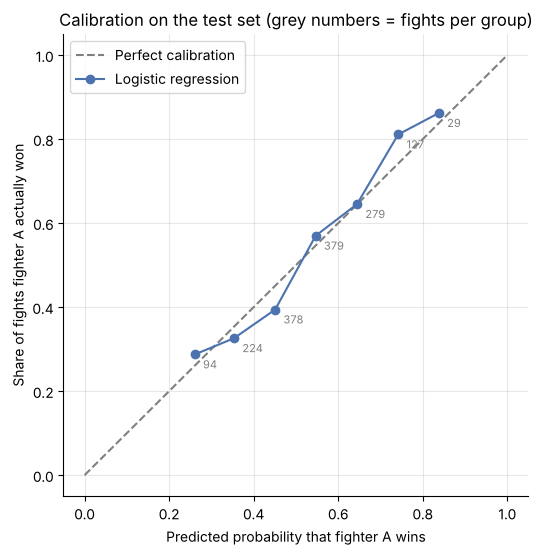

In [41]:
calibration = pd.DataFrame({"predicted": prob_test, "won": y_test.to_numpy()})
calibration["bin"] = pd.cut(calibration["predicted"], bins=np.linspace(0, 1, 11))
calibration = calibration.groupby("bin", observed=True).agg(
    predicted=("predicted", "mean"), actual=("won", "mean"), fights=("won", "size"))
calibration = calibration[calibration["fights"] >= 20]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
ax.plot(calibration["predicted"], calibration["actual"], marker="o", color="#4C72B0", label="Logistic regression")
for _, row in calibration.iterrows():
    ax.annotate(f"{row['fights']:.0f}", (row["predicted"], row["actual"]),
                textcoords="offset points", xytext=(6, -10), fontsize=8, color="grey")
ax.set_xlabel("Predicted probability that fighter A wins")
ax.set_ylabel("Share of fights fighter A actually won")
ax.set_title("Calibration on the test set (grey numbers = fights per group)")
ax.legend()
plt.show()

**Observation.** The points lie close to the diagonal, so the probabilities are well calibrated: fights the model rates at about 55–65% for fighter A are won by A about that often. At the top end the model is slightly **cautious**, because favourites it gave about 75% actually won about 80% of the time. It almost never gives probabilities below 25% or above 85%, which is honest. MMA is unpredictable, and even strong favourites lose often.

### 9.7 What the model learned

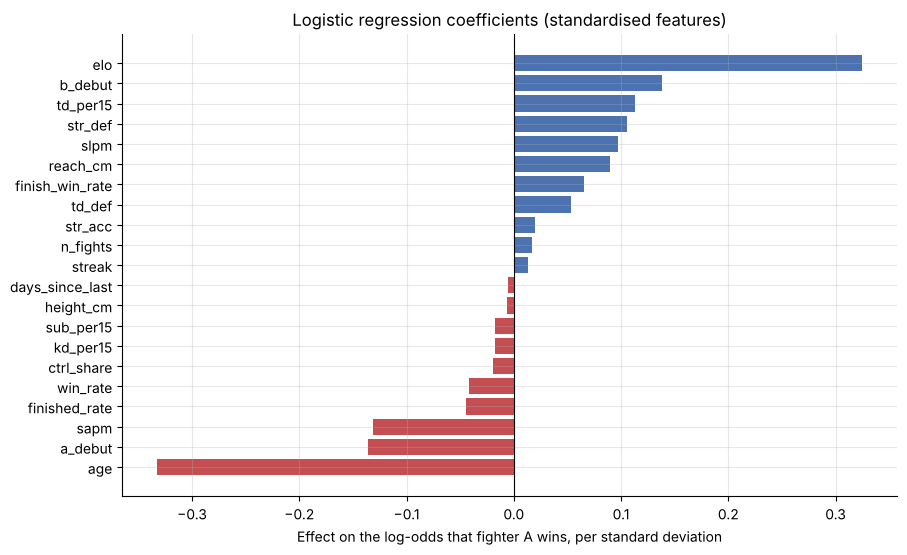

In [42]:
coefficients = pd.Series(logreg[-1].coef_[0], index=MODEL_COLUMNS).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = np.where(coefficients > 0, "#4C72B0", "#C44E52")
ax.barh([c.replace("diff_", "") for c in coefficients.index], coefficients.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic regression coefficients (standardised features)")
ax.set_xlabel("Effect on the log-odds that fighter A wins, per standard deviation")
plt.show()

**How to read this chart.** Each bar shows how a one-standard-deviation increase in A's advantage on that feature changes the chance that A wins, with all other features held fixed. Blue bars help A win, and red bars hurt. Because the features overlap (for example, Elo, win rate and streak all measure past success), individual coefficients should be read with care: the model spreads the credit between related features.

**What the model learned.**

- **Elo rating** has the largest positive effect: a better record against strong opponents is the best single sign of who will win.
- **Age** has the largest negative effect: the older fighter is less likely to win, all else being equal. This explains why "pick the more experienced fighter" failed as a baseline.
- **Debut flags:** a fighter making their debut is at a disadvantage (`a_debut` is negative, and an opponent's debut, `b_debut`, helps A).
- **Style statistics:** more takedowns per 15 minutes, better striking defence, more strikes landed and a longer reach help. Absorbing more strikes per minute (`sapm`) hurts.
- **Small or surprising coefficients**, such as a slightly negative `win_rate`, come from overlap with Elo. Once Elo is in the model, win rate adds almost nothing, and the model spreads the credit between the two. These shouldn't be read as "a better win rate is bad".

### 9.8 Why the leakage rule matters: a demonstration

What if the 2026 snapshot statistics from the `fighter` table had been used instead (strikes per minute, accuracy, takedowns and so on), as many online notebooks do? The cell below trains the same kind of model on those snapshot statistics alone.

In [43]:
SNAPSHOT_COLUMNS = ["slpm", "str_acc", "sapm", "str_def", "td_avg", "td_acc", "td_def", "sub_avg"]
snapshot = query(f"SELECT fighter_id, {', '.join(SNAPSHOT_COLUMNS)} FROM fighter").set_index("fighter_id")
leaky = (snapshot.reindex(model_data["a_id"]).reset_index(drop=True)
         - snapshot.reindex(model_data["b_id"]).reset_index(drop=True)).fillna(0).add_prefix("snapshot_")

leaky_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
leaky_model.fit(leaky[model_data["event_date"] < TEST_START], y_train)
leaky_prob = leaky_model.predict_proba(leaky[model_data["event_date"] >= TEST_START])[:, 1]

print(f"Leaky model (2026 snapshot stats): accuracy {accuracy_score(y_test, leaky_prob >= 0.5):.1%}, "
      f"ROC AUC {roc_auc_score(y_test, leaky_prob):.3f}")
print(f"Honest model (pre-fight features): accuracy {RESULTS['Logistic regression']['accuracy']:.1%}, "
      f"ROC AUC {RESULTS['Logistic regression']['ROC AUC']:.3f}")

Leaky model (2026 snapshot stats): accuracy 70.7%, ROC AUC 0.790
Honest model (pre-fight features): accuracy 64.7%, ROC AUC 0.693


**Observation.** The leaky model looks clearly better than the honest one. That is exactly the trap. The snapshot statistics were measured *after* the test fights took place, so they already contain the results of those fights. A fighter who won most of their fights in 2024–2026 has better 2026 statistics *because* they won. This model could never be used before a real fight, because those statistics don't exist yet. Its score is an illusion, which is why every feature in this project is rebuilt from earlier fights only.

### 9.9 Improving the model

Can the model predict better? Every idea below is judged **only on the training years** (April 2010 to December 2023), using the same 5-fold time-series cross-validation as in Section 9.5. The test set is used **once**, at the end, for the final chosen model. Trying many ideas on the test set and keeping the best would mean the test score no longer measures how the model does on unseen fights.

A reminder of the scale involved: with about 1,500 test fights, a test accuracy has a margin of error of roughly ±2.4 percentage points (95% confidence). Improvements of a point or two are hard to separate from luck.

In [44]:
def cv_score(X, y, make_model, n_splits=5):
    """Average accuracy and log loss over time-series CV folds of the training data."""
    accuracies, losses = [], []
    for fit_idx, val_idx in TimeSeriesSplit(n_splits=n_splits).split(X):
        model = make_model()
        model.fit(X.iloc[fit_idx], y.iloc[fit_idx])
        prob = model.predict_proba(X.iloc[val_idx])[:, 1]
        accuracies.append(accuracy_score(y.iloc[val_idx], prob >= 0.5))
        losses.append(log_loss(y.iloc[val_idx], prob))
    return np.mean(accuracies), np.mean(losses)


def logistic(C=0.01):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))


is_train = (model_data["event_date"] < TEST_START).to_numpy()
y_all = model_data["a_won"]
experiments = {}
experiments["Current model (Section 9.5)"] = cv_score(model_data.loc[is_train, MODEL_COLUMNS], y_train, logistic)

#### Idea 1: a better Elo rating

Elo is the model's strongest feature, so improving it should help most. Three changes are tested, each based on how MMA works:

- **Margin of victory:** a knockout or submission is more convincing than a split decision. The update is multiplied by 1.25 for a finish and by 0.5 for a split or majority decision.
- **Layoffs:** a fighter who hasn't fought for a long time may not be the fighter they were. For every year out beyond the first, the rating is pulled back towards 1500 by a share (`decay`).
- **K** is re-checked with these changes.

As in Section 8.2, each version is scored by how often the higher-rated fighter won during the training period.

In [45]:
fights_m = query("SELECT fight_id, event_date, r_id, b_id, winner_id, result_status, method FROM fight_info")
fights_m["event_date"] = pd.to_datetime(fights_m["event_date"])
FINISH_METHODS = {"KO/TKO", "Submission", "TKO - Doctor's Stoppage"}
CLOSE_DECISIONS = {"Decision - Split", "Decision - Majority"}


def pre_fight_elo_v2(fights, k, finish_mult=1.0, close_mult=1.0, decay=0.0):
    """Elo with margin-of-victory multipliers and a pull back to the start rating after layoffs."""
    ratings, last_date, before = {}, {}, {}
    for date, day in fights.sort_values("event_date").groupby("event_date", sort=True):
        snapshot = {}
        for fight in day.itertuples():
            for fighter in (fight.r_id, fight.b_id):
                rating = ratings.get(fighter, ELO_START)
                if decay and fighter in last_date:
                    years_out = (date - last_date[fighter]).days / 365.25
                    if years_out > 1:
                        rating = ELO_START + (rating - ELO_START) * (1 - decay) ** (years_out - 1)
                snapshot[fighter] = rating
            before[(fight.fight_id, fight.r_id)] = snapshot[fight.r_id]
            before[(fight.fight_id, fight.b_id)] = snapshot[fight.b_id]
        for fight in day.itertuples():
            if fight.result_status == "no_contest":
                continue
            expected_r = 1 / (1 + 10 ** ((snapshot[fight.b_id] - snapshot[fight.r_id]) / 400))
            score_r = 0.5 if fight.result_status == "draw" else float(fight.winner_id == fight.r_id)
            mult = (finish_mult if fight.method in FINISH_METHODS
                    else close_mult if fight.method in CLOSE_DECISIONS else 1.0)
            for fighter, score, expected in ((fight.r_id, score_r, expected_r),
                                             (fight.b_id, 1 - score_r, 1 - expected_r)):
                ratings[fighter] = snapshot[fighter] + k * mult * (score - expected)
                last_date[fighter] = date
    return before


ELO_VARIANTS = {
    "Section 8.2 (K=200)": dict(k=200),
    "+ margin of victory": dict(k=200, finish_mult=1.25, close_mult=0.5),
    "+ layoff decay 0.4": dict(k=200, decay=0.4),
    "+ both (K=200)": dict(k=200, finish_mult=1.25, close_mult=0.5, decay=0.4),
    "+ both (K=150)": dict(k=150, finish_mult=1.25, close_mult=0.5, decay=0.4),
    "+ both, decay 0.6": dict(k=200, finish_mult=1.25, close_mult=0.5, decay=0.6),
}
elo_variant_scores = {}
for label, settings in ELO_VARIANTS.items():
    before = pre_fight_elo_v2(fights_m, **settings)
    elo_variant_scores[label] = elo_pick_accuracy(before, train_fights)
pd.Series(elo_variant_scores, name="higher Elo wins (training period)").map("{:.1%}".format).to_frame()

,higher Elo wins (training period)
Section 8.2 (K=200),57.8%
+ margin of victory,58.4%
+ layoff decay 0.4,58.5%
+ both (K=200),59.1%
+ both (K=150),59.2%
"+ both, decay 0.6",59.2%


**Observation.** Both changes help, and together they raise the share of training fights won by the higher-rated fighter by about one percentage point. The last three versions are within about 0.1 percentage points of each other, which is noise. The chosen version is **K = 200, finishes ×1.25, close decisions ×0.5, layoff decay 0.4**, which keeps the K from Section 8.2.

In [46]:
ELO_V2_SETTINGS = dict(k=200, finish_mult=1.25, close_mult=0.5, decay=0.4)
elo_v2_before = pre_fight_elo_v2(fights_m, **ELO_V2_SETTINGS)
features["elo_v2"] = [elo_v2_before[(f, a)] for f, a in zip(features["fight_id"], features["fighter_id"])]

#### Idea 2: extra features

Several more pre-fight features were built, again only from fights on earlier dates:

| Feature | Meaning |
|---|---|
| `form3` | Win rate over the last 3 fights (recent form) |
| `career_years` | Years since the fighter's first fight in the dataset |
| `layoff_long` | 1 if the fighter has been out for more than a year |
| `recent_slpm`, `recent_sapm` | Strikes landed / absorbed per minute over the last 3 fights |
| `opp_strength` | Average Elo of previous opponents (strength of schedule) |

In [47]:
def recent_form(fighter_fights, elo_before):
    """Last-3-fights form, career length and strength of schedule, from earlier dates only."""
    df = fighter_fights.copy()
    df["fights"] = 1
    df["opp_elo"] = [elo_before[(f, o)] for f, o in zip(df["fight_id"], df["opponent_id"])]
    per_date = (df.groupby(["fighter_id", "event_date"])
                  .agg(fights=("fights", "sum"), win=("win", "sum"), opp_elo=("opp_elo", "sum"),
                       minutes=("minutes", lambda s: s.sum(min_count=1)),
                       sig_landed=("sig_landed", lambda s: s.sum(min_count=1)),
                       sig_absorbed=("sig_absorbed", lambda s: s.sum(min_count=1)))
                  .reset_index().sort_values(["fighter_id", "event_date"]))
    by_fighter = per_date.groupby("fighter_id")

    def last3(column):
        return by_fighter[column].transform(lambda s: s.shift(1).rolling(3, min_periods=1).sum())

    out = per_date[["fighter_id", "event_date"]].copy()
    fights3 = last3("fights")
    out["form3"] = last3("win") / fights3.where(fights3 > 0)
    minutes3 = last3("minutes").where(last3("minutes") >= MIN_STAT_MINUTES)
    out["recent_slpm"] = last3("sig_landed") / minutes3
    out["recent_sapm"] = last3("sig_absorbed") / minutes3
    previous = by_fighter["fights"].transform(lambda s: s.cumsum().shift(1, fill_value=0))
    out["opp_strength"] = (by_fighter["opp_elo"].transform(lambda s: s.cumsum().shift(1, fill_value=0))
                           / previous.where(previous > 0))
    out["career_years"] = (per_date["event_date"] - by_fighter["event_date"].transform("min")).dt.days / 365.25
    return out


features = features.drop(columns=["form3", "recent_slpm", "recent_sapm", "opp_strength", "career_years"],
                         errors="ignore").merge(recent_form(fighter_fights, elo_v2_before),
                                                on=["fighter_id", "event_date"], how="left")
features["layoff_long"] = (features["days_since_last"] > 365).astype(float)

EXTRA = ["form3", "career_years", "layoff_long", "recent_slpm", "recent_sapm", "opp_strength"]
X_all = features.set_index(["fight_id", "fighter_id"])
A_all = X_all.loc[list(zip(model_data["fight_id"], model_data["a_id"]))].reset_index(drop=True)
B_all = X_all.loc[list(zip(model_data["fight_id"], model_data["b_id"]))].reset_index(drop=True)


def design_matrix(feature_list):
    """A-minus-B differences (missing -> 0) plus the debut flags."""
    diff = (A_all[feature_list] - B_all[feature_list]).add_prefix("diff_").fillna(0)
    return pd.concat([diff, model_data[["a_debut", "b_debut"]].reset_index(drop=True)], axis=1)


BASE_V2 = ["elo_v2"] + [f for f in FEATURES if f != "elo"]
CANDIDATES = {
    "Better Elo": BASE_V2,
    "Better Elo + form3, career_years, layoff_long": BASE_V2 + ["form3", "career_years", "layoff_long"],
    "Better Elo + all extra features": BASE_V2 + EXTRA,
}
for label, feature_list in CANDIDATES.items():
    X_candidate = design_matrix(feature_list)
    experiments[label] = cv_score(X_candidate[is_train].reset_index(drop=True), y_train.reset_index(drop=True), logistic)

#### Idea 3: other models

**Gradient boosting** and **random forests** are tree-based models that can learn non-linear patterns and interactions, such as "a reach advantage matters more for strikers". They are tried on the full feature set. Gradient boosting (`HistGradientBoostingClassifier`) can also handle missing values directly, so it gets the raw differences without the 0-filling.

In [48]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

all_features = BASE_V2 + EXTRA
X_raw = pd.concat([(A_all[all_features] - B_all[all_features]).add_prefix("diff_"),
                   model_data[["a_debut", "b_debut"]].reset_index(drop=True)], axis=1)
X_filled = design_matrix(all_features)
y_reset = y_train.reset_index(drop=True)

experiments["Gradient boosting (all features)"] = cv_score(
    X_raw[is_train].reset_index(drop=True), y_reset,
    lambda: HistGradientBoostingClassifier(learning_rate=0.03, max_depth=3, max_iter=300,
                                           l2_regularization=1.0, random_state=RANDOM_SEED))
experiments["Random forest (all features)"] = cv_score(
    X_filled[is_train].reset_index(drop=True), y_reset,
    lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_SEED))

experiment_table = pd.DataFrame(experiments, index=["CV accuracy", "CV log loss"]).T
experiment_table.style.format({"CV accuracy": "{:.1%}", "CV log loss": "{:.4f}"})

,CV accuracy,CV log loss
Current model (Section 9.5),60.5%,0.6582
Better Elo,60.9%,0.6563
"Better Elo + form3, career_years, layoff_long",61.7%,0.6548
Better Elo + all extra features,61.4%,0.6545
Gradient boosting (all features),59.3%,0.6667
Random forest (all features),60.5%,0.6596


**Observation.**

- **The better Elo rating** improves both accuracy and log loss.
- **Recent form, career length and the long-layoff flag** add a little more, and this combination has the best cross-validated accuracy.
- **Adding every extra feature** gives a similar log loss but slightly lower accuracy. More features means more noise for the model to fit.
- **Gradient boosting and the random forest do no better than the original logistic regression, and worse than the improved one.** Gradient boosting has the worst accuracy and log loss in the table. The signal in fight data is weak and mostly linear ("better record and younger is better"). With only a few thousand training fights, the flexibility of tree models mostly lets them fit noise.

**Chosen model:** logistic regression with the better Elo rating plus `form3`, `career_years` and `layoff_long`. `C` is re-tuned with time-series CV, as in Section 9.5.

#### Final evaluation on the test set (used once)

In [49]:
FINAL_FEATURES = CANDIDATES["Better Elo + form3, career_years, layoff_long"]
X_final = design_matrix(FINAL_FEATURES)
X_final_train, X_final_test = X_final[is_train], X_final[~is_train]

final_search = GridSearchCV(logistic(), {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1]},
                            cv=TimeSeriesSplit(n_splits=5), scoring="neg_log_loss")
final_search.fit(X_final_train, y_train)
final_model = final_search.best_estimator_
print(f"Best C = {final_search.best_params_['logisticregression__C']}")

prob_final = final_model.predict_proba(X_final_test)[:, 1]
evaluate("Improved logistic regression", y_test, prob_a=prob_final)

final_table = pd.DataFrame(RESULTS).T.sort_values("accuracy", ascending=False)
final_table.style.format({"accuracy": "{:.1%}", "log loss": "{:.3f}", "ROC AUC": "{:.3f}",
                          "Brier score": "{:.3f}"}, na_rep="–")

Best C = 0.01


,accuracy,log loss,ROC AUC,Brier score
Improved logistic regression,65.3%,0.629,0.706,0.219
Logistic regression,64.7%,0.635,0.693,0.222
Younger fighter,60.1%,–,–,–
Better win rate,60.1%,–,–,–
Higher Elo rating,58.4%,–,–,–
Coin flip,49.3%,–,–,–
More experienced fighter,45.6%,–,–,–


In [50]:
from scipy.stats import binomtest

old_right = (prob_test >= 0.5) == y_test.to_numpy()
new_right = (prob_final >= 0.5) == y_test.to_numpy()
only_new, only_old = int((new_right & ~old_right).sum()), int((old_right & ~new_right).sum())
p_value = binomtest(only_new, only_new + only_old, 0.5).pvalue
accuracy = RESULTS["Improved logistic regression"]["accuracy"]
margin = 1.96 * np.sqrt(accuracy * (1 - accuracy) / len(y_test))

print(f"Test accuracy: {accuracy:.1%} ± {margin:.1%} (95% confidence)")
print(f"Fights where only the improved model was right: {only_new}; only the original: {only_old}")
print(f"McNemar (exact binomial) test p-value: {p_value:.2f}")

Test accuracy: 65.3% ± 2.4% (95% confidence)
Fights where only the improved model was right: 59; only the original: 49
McNemar (exact binomial) test p-value: 0.39


**Observation.** The improved model is better on every metric (accuracy, log loss, ROC AUC and Brier score), in line with the cross-validation results. The improvement is small, though. The two models disagree on only about a hundred test fights, and the **McNemar test** (which compares two models on the same fights) can't rule out that the difference is luck (p well above 0.05). The honest conclusion is that the improvements are consistent but modest. The remaining gap is mostly information the dataset doesn't contain (Section 10).

#### Where the model is most useful: confident predictions

Overall accuracy treats every fight the same, but many fights are close to 50/50 for anyone. The table shows how accurate the improved model is when it is more confident.

In [51]:
confidence = np.maximum(prob_final, 1 - prob_final)
rows = []
for threshold in [0.5, 0.6, 0.65, 0.7, 0.75]:
    chosen = confidence >= threshold
    rows.append({"model confidence at least": f"{threshold:.0%}",
                 "share of fights": chosen.mean(),
                 "fights": int(chosen.sum()),
                 "accuracy": new_right[chosen].mean()})
pd.DataFrame(rows).style.format({"share of fights": "{:.0%}", "accuracy": "{:.1%}"}).hide(axis="index")

model confidence at least,share of fights,fights,accuracy
50%,100%,1528,65.3%
60%,54%,821,73.1%
65%,35%,538,74.3%
70%,20%,298,78.9%
75%,10%,147,82.3%


**Observation.** Accuracy rises steadily with confidence. When the model gives one fighter at least a 70% chance, which happens in roughly one fight in five, it picks the winner nearly 80% of the time. For the closest fights (confidence between 50% and 60%) it is right only about 56% of the time, a little better than a coin flip. This matches the calibration in Section 9.6, and it's a more useful way to report the model than a single accuracy figure: it says *which* predictions can be trusted.

## 10. Conclusion

**Question.** Can engineered features built only from information known before a fight predict its winner better than a simple baseline?

**Answer.** Yes, modestly. On fights from January 2024 to August 2026, which the model never saw, logistic regression on pre-fight features picked the winner more often than any simple rule, and its probabilities were well calibrated. The improved model (Section 9.9) is the best version, about 5 percentage points ahead of the best simple rule. Its real strength is in confident predictions: when it gives a fighter at least a 70% chance, it is right nearly 80% of the time. MMA fights are hard to predict from statistics alone, and many fights are close to a coin flip.

**What the work showed.**

1. **Most of the effort was in data preparation, not the model.** The dataset contains three serious traps: a red corner that "always wins" before 2010, career statistics captured after the fights they would be used to predict, and missing statistics stored as zeros. Each would have produced a model that looked good and didn't work. Section 9.8 showed the effect of one of them.
2. **Record quality and age matter most.** The Elo rating and the fighters' ages have the largest effects. Experience on its own is not an advantage: the more experienced fighter wins *less* than half the time, mainly because experienced fighters are older. Debutants are at a disadvantage.
3. **Style statistics add a little.** Takedowns, striking defence, striking output and reach help, and absorbing many strikes hurts, but they add less than record and age.
4. **The probabilities are honest.** The model is rarely very confident, which matches how unpredictable the sport is, and its confident predictions are much more accurate than its uncertain ones.
5. **Improvements came from better features, not more complex models.** A better Elo rating (margin of victory and layoff decay) and recent form helped. Gradient boosting and random forests did worse than logistic regression on this data. All improvements were chosen on the training years only, and the gain is consistent but too small to be statistically certain on one test set.

**Limitations.**

- **No betting odds.** Bookmakers' odds combine much more information (injuries, training camps, weight cuts, styles). They would be the real benchmark, but the dataset doesn't contain them.
- **Debutants.** About a third of fighters have only one fight in the dataset, so for many fights one fighter has little or no history.
- **Missing values set to 0.** This is simple but crude. A missing statistic isn't really "the same as the opponent".
- **Physical data** (reach in particular) is often missing, and ages are unknown for some fighters.
- **One random order.** Results depend slightly on the random A/B assignment (`RANDOM_SEED`). Averaging over both orders would remove this.

**Future work.** Betting odds or expert rankings could be added as a benchmark, or as features where they would be known before a fight. Fighter-specific information such as injuries, short-notice replacements and weight cuts would probably help more than further tuning. Other classification models covered later in the module can be compared using exactly the same features, train/test split and baselines.

In [52]:
conn.close()

## References

- UFC Stats. *Official UFC fight statistics.* http://www.ufcstats.com (scraped 11 August 2026; Kaggle dataset: *[add author and URL]*)
- Elo, A. E. (1978). *The Rating of Chessplayers, Past and Present.* Arco. (Elo rating system)
- scikit-learn documentation: `LogisticRegression`, `StandardScaler`, `TimeSeriesSplit`, `GridSearchCV`, metrics. https://scikit-learn.org/stable/
- Python Software Foundation. *sqlite3: DB-API 2.0 interface for SQLite databases.* https://docs.python.org/3/library/sqlite3.html
- SQLite. *SQL As Understood By SQLite* (views, CASE, window-free aggregation). https://www.sqlite.org/lang.html